# EKF G/F con solubilidad variable · Efecto de la cuarta fuente de ruido

Se compara el EKF de [05_zenteno_co2_variable_solubility](../05_zenteno_co2_variable_solubility.source.ipynb) con y sin la fuente de incertidumbre adicional en la producción de CO₂. Ambos casos usan \(R=0{,}00218\) fijo en \((\mathrm{g/(L\cdot h)})^2\), los mismos datos, condiciones iniciales, parámetros y balances. LAB019–021 corresponden al conjunto de desarrollo y LAB016–018 al conjunto de validación.

Para aislar el efecto de la cuarta fuente se usan las amplitudes de referencia. La comparación cambia \(D_{44}\) de \(10^{-4}\) a cero y mantiene las amplitudes de crecimiento y de las dos fermentaciones.

In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nbformat
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
HERE=ROOT/'notebooks/EKF/kalman_analysis'
sys.path.insert(0,str(HERE))
import analysis_core as core
INSTRUMENT=json.loads((ROOT/'configs/co2_instrument.json').read_text())
assert INSTRUMENT['flow_range_sccm']==[0.,50.] and INSTRUMENT['calibration_gas']=='air'
assert INSTRUMENT['co2_correction_factor']==.74
DATA,CHEM,AUDIT,_=core.prepare(ROOT)
assert tuple(DATA)==('LAB019','LAB020','LAB021') and set(CHEM.lab)==set(DATA)
DEVELOPMENT=tuple(DATA)
HOLDOUT=('LAB016','LAB017','LAB018')
LABS=DEVELOPMENT+HOLDOUT
ROLE={lab:('Development' if lab in DEVELOPMENT else 'Holdout') for lab in LABS}
# Reuse the same clock corrections, horizons and holdout metadata as EKF05.
# load() prepares observations and metadata; it does not calibrate gas or chemistry.
sys.path.insert(0,str(ROOT/'src'))
from wine_fermentation.models.historical.calibration import load
v=load(ROOT)
volume_rows=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L'])
extra_audit=[]
for lab in HOLDOUT:
    horizon=float(v.horizons[lab]);batch=v.batches[lab]
    events=list(batch.pulses['N'])
    if lab=='LAB017':events=[(min(t for t,dose in events),sum(dose for t,dose in events))]
    events=np.array([(round(t,10),dose) for t,dose in events],float)
    ev=volume_rows.loc[volume_rows.lab.eq(lab)&volume_rows.record_kind.eq('withdrawal_after')].sort_values('time_h')
    et=ev.time_h.to_numpy();vv=ev.remaining_volume_L.to_numpy()
    def volume(t):return np.r_[2.,vv][np.searchsorted(et,np.asarray(t),side='right')]
    raw=v.raw_co2[lab].copy();raw['bin']=np.ceil(raw.t_h/.5-1e-10).astype(int);rows=[]
    for end in np.arange(.5,horizon+1e-9,.5):
        sample=raw.loc[raw.bin.eq(round(end/.5))].dropna(subset=['flow_sccm'])
        gaps=np.diff(np.r_[end-.5,sample.t_h.to_numpy(),end])
        y=sample.flow_sccm.to_numpy()*(44.0095*60*.74/(1000*24.16))/volume(sample.t_h.to_numpy())
        rows.append((end,float(np.mean(y)) if len(y) else np.nan,len(sample)>=30 and gaps.max()<=2/60))
    sensor=pd.DataFrame(rows,columns=['t_h','measured','valid'])
    sensor['assimilate']=sensor.valid&sensor.measured.ge(.05)&sensor.valid.shift(fill_value=False)&sensor.measured.shift().ge(.05)
    rawt=v.raw_temperature[lab].copy();rawt['minute']=np.floor(rawt.t_h*60).astype(int)
    temp=rawt.groupby('minute')['T'].median().dropna();available=(temp.index.to_numpy()+1)/60;temps=temp.to_numpy(float)
    initial=np.array([batch.initials[k] for k in core.STATES[:5]]+[0.,0.]);initial[4]=10.010194;S0=initial[2]+initial[3]
    r=initial[2]/S0
    P0=np.diag([max(.03,.2*initial[0])**2,.015**2,r*r*25+25,(1-r)**2*25+25,4.,0.,0.]);P0[2,3]=P0[3,2]=r*(1-r)*25-25
    grid=np.unique(np.round(np.r_[np.arange(0,horizon,1/12),sensor.t_h,horizon,events[:,0]],10))
    doses=np.zeros(len(grid));obs=np.full(len(grid),np.nan);valid=np.zeros(len(grid),bool);update=np.zeros(len(grid),bool)
    for t,dose in events:doses[np.argmin(abs(grid-t))]+=dose
    for row in sensor.itertuples():
        j=np.argmin(abs(grid-row.t_h));assert abs(grid[j]-row.t_h)<1e-8
        obs[j]=row.measured;valid[j]=row.valid;update[j]=row.assimilate
    DATA[lab]=dict(grid=grid,doses=doses,y=obs,valid=valid,update=update,initial=initial,P0=P0,available=available,temperature=temps,S0=S0,sensor=sensor,horizon=horizon)
    extra_audit.append(dict(LAB=lab,horizon_h=horizon,windows=len(sensor),updates=int(sensor.assimilate.sum()),X0=initial[0],N0=initial[1],G0=initial[2],F0=initial[3],E0=initial[4],pulse_h=events[0,0],dose_g_L=events[0,1]))
# Only actual holdout biomass observations are appended; missing chemistry is not invented.
CHEM=pd.concat([CHEM,v.biomass.loc[v.biomass.lab.isin(HOLDOUT),['lab','t_h','X_viable_g_l']]],ignore_index=True)
DENSITY=v.density.loc[v.density.lab.isin(LABS)].copy()
AUDIT=pd.concat([AUDIT,pd.DataFrame(extra_audit)],ignore_index=True);AUDIT['role']=AUDIT.LAB.map(ROLE)
assert tuple(DATA)==LABS
display(AUDIT)


,LAB,horizon_h,windows,updates,X0,N0,G0,F0,E0,pulse_h,dose_g_L,role
0,LAB019,166.000000,332,217,0.283162,0.230025,79.190000,78.970000,10.010194,64.333333,0.086486,Development
1,LAB020,172.333333,344,223,0.153342,0.225556,77.940000,79.520000,10.010194,71.666667,0.088889,Development
2,LAB021,166.000000,332,166,0.270000,0.231202,80.190000,81.040000,10.010194,47.500000,0.086486,Development
3,LAB016,151.100000,302,249,0.390000,0.214330,84.158815,88.341185,10.010194,56.935556,0.140000,Holdout
4,LAB017,141.000000,282,213,0.390000,0.214330,84.158815,88.341185,10.010194,56.933611,0.280000,Holdout
5,LAB018,141.000000,282,237,0.390000,0.214330,84.158815,88.341185,10.010194,56.931667,0.140000,Holdout


Las columnas de \(L_k\) distribuyen el ruido de cada fuente entre los estados. En cada paso el EKF incorpora \(Q_k \approx \Delta t_k L_k D L_k^\top\), con el escalado interno de los estados. La cuarta columna representa una incertidumbre adicional en la producción predicha de CO₂ y actúa directamente sobre el CO₂ disuelto o emitido, según la rama activa del balance. Al fijar \(D_{44}=0\), el CO₂ conserva la incertidumbre que le transmiten el crecimiento y las dos fermentaciones. Las amplitudes se mantienen fijas durante cada ejecución.

In [2]:
R = 0.00218
WITH_SOURCE = 'Cuatro fuentes'
WITHOUT_SOURCE = 'Tres fuentes'
four_sources = core.BASE_SIGMA.copy()
three_sources = four_sources.copy()
three_sources[3] = 0.0
np.testing.assert_array_equal(four_sources, [0.003, 0.08, 0.08, 0.01, 0.0, 0.0])
CASES = {WITH_SOURCE: four_sources, WITHOUT_SOURCE: three_sources}

D = pd.DataFrame(
    {case: amplitudes[:4]**2 for case, amplitudes in CASES.items()},
    index=['Crecimiento', 'Fermentación de glucosa', 'Fermentación de fructosa', 'Producción adicional de CO₂'],
)
display(D.style.format('{:.2e}').set_caption('Entradas diagonales de D por fuente'))


,Cuatro fuentes,Tres fuentes
Crecimiento,9.00e-06,9.00e-06
Fermentación de glucosa,6.40e-03,6.40e-03
Fermentación de fructosa,6.40e-03,6.40e-03
Producción adicional de CO₂,1.00e-04,0.00e+00


In [3]:
RESULTS = {case: {} for case in CASES}
metric_rows, checks = [], []
for lab in LABS:
    for case, amplitudes in CASES.items():
        result = core.run(DATA[lab], sigma=amplitudes, Rsd=np.sqrt(R))
        RESULTS[case][lab] = result
        metrics, info, _ = core.diagnostics(DATA, CHEM, lab, result)
        metric_rows.append(metrics.assign(caso=case, grupo=ROLE[lab]))
        checks.append(dict(info, caso=case, grupo=ROLE[lab]))

METRICS = pd.concat(metric_rows, ignore_index=True)
CHECKS = pd.DataFrame(checks)
keys = ['grupo', 'LAB', 'variable', 'unit']
counts = METRICS.pivot(index=keys, columns='caso', values='n')
assert counts[WITH_SOURCE].equals(counts[WITHOUT_SOURCE])
assert CHECKS.min_eigenvalue.min() > -1e-7
for lab in LABS:
    expected_updates = DATA[lab]['update']
    for case in CASES:
        diagnostics = RESULTS[case][lab][2]
        np.testing.assert_array_equal(diagnostics[:, 5] == 1, expected_updates)
    # Confirm that switching off the source has a measurable effect on the replay.
    assert np.any(RESULTS[WITH_SOURCE][lab][0] != RESULTS[WITHOUT_SOURCE][lab][0])

def add_delta(table):
    return table.assign(**{'Cambio al quitar la cuarta fuente (%)': 100 * (table[WITHOUT_SOURCE] / table[WITH_SOURCE] - 1)})

for metric in ('RMSE', 'MAE'):
    grouped = METRICS.groupby(['grupo', 'variable', 'unit', 'caso'])[metric].mean().unstack('caso')
    by_lab = METRICS.pivot(index=keys, columns='caso', values=metric)
    print(f'{metric} medio por grupo. Cada lote tiene el mismo peso.')
    display(add_delta(grouped[[WITH_SOURCE, WITHOUT_SOURCE]]).round(5))
    print(f'{metric} por lote. X corresponde a biomasa.')
    display(add_delta(by_lab[[WITH_SOURCE, WITHOUT_SOURCE]]).round(5))
print('Diagnosticos por lote en las ventanas asimiladas.')
display(CHECKS[['grupo', 'LAB', 'caso', 'updates', 'mean_NIS',
                'innovation_coverage95', 'lag1', 'clips']].round(4))

RMSE medio por grupo. Cada lote tiene el mismo peso.
RMSE por lote. X corresponde a biomasa.
MAE medio por grupo. Cada lote tiene el mismo peso.
MAE por lote. X corresponde a biomasa.
Diagnosticos por lote en las ventanas asimiladas.


caso                          Cuatro fuentes  ...  Cambio al quitar la cuarta fuente (%)
grupo       variable unit                     ...                                       
Development CO2      g/(L h)         0.07399  ...                                0.11646
            E        g/L             3.65460  ...                               -0.53817
            F        g/L             5.32106  ...                                0.13442
            G        g/L             4.99128  ...                               -0.15398
            GF       g/L             8.18114  ...                                0.02497
            N        mg/L           17.12185  ...                                0.13498
            X        g/L             0.71986  ...                                0.06575
Holdout     CO2      g/(L h)         0.08002  ...                               -0.12331
            X        g/L             0.61737  ...                                0.02900

[9 rows x 3 columns]

caso                                 Cuatro fuentes  ...  Cambio al quitar la cuarta fuente (%)
grupo       LAB    variable unit                     ...                                       
Development LAB019 CO2      g/(L h)         0.06390  ...                                0.13485
                   E        g/L             4.31327  ...                               -0.19090
                   F        g/L             5.33387  ...                                0.37777
                   G        g/L             4.24205  ...                               -0.57616
                   GF       g/L             7.98078  ...                                0.00693
                   N        mg/L           20.01483  ...                                0.16154
                   X        g/L             0.65490  ...                                0.06981
            LAB020 CO2      g/(L h)         0.07034  ...                                0.30553
                   E        g/L             3.52061  ...                               -0.33003
                   F        g/L             6.08464  ...                                0.13408
                   G        g/L             4.53780  ...                               -0.36683
                   GF       g/L             8.25181  ...                                0.06162
                   N        mg/L           18.11179  ...                                0.21577
                   X        g/L             0.57051  ...                                0.04408
            LAB021 CO2      g/(L h)         0.08772  ...                               -0.04855
                   E        g/L             3.12991  ...                               -1.25085
                   F        g/L             4.54467  ...                               -0.15072
                   G        g/L             6.19400  ...                                0.29109
                   GF       g/L             8.31084  ...                                0.00590
                   N        mg/L           13.23893  ...                               -0.01571
                   X        g/L             0.93417  ...                                0.07613
Holdout     LAB016 CO2      g/(L h)         0.07386  ...                               -0.36186
                   X        g/L             0.56065  ...                                0.04134
            LAB017 CO2      g/(L h)         0.08750  ...                                0.12934
                   X        g/L             0.81125  ...                                0.03749
            LAB018 CO2      g/(L h)         0.07870  ...                               -0.18034
                   X        g/L             0.48022  ...                                0.00026

[27 rows x 3 columns]

caso                          Cuatro fuentes  ...  Cambio al quitar la cuarta fuente (%)
grupo       variable unit                     ...                                       
Development CO2      g/(L h)         0.05176  ...                                0.12007
            E        g/L             3.15985  ...                               -0.64898
            F        g/L             4.94283  ...                                0.14533
            G        g/L             4.27193  ...                               -0.15898
            GF       g/L             7.37431  ...                                0.06151
            N        mg/L           12.74216  ...                                0.07685
            X        g/L             0.53484  ...                                0.12787
Holdout     CO2      g/(L h)         0.06080  ...                               -0.09009
            X        g/L             0.56702  ...                                0.02091

[9 rows x 3 columns]

caso                                 Cuatro fuentes  ...  Cambio al quitar la cuarta fuente (%)
grupo       LAB    variable unit                     ...                                       
Development LAB019 CO2      g/(L h)         0.04792  ...                                0.08932
                   E        g/L             3.41110  ...                               -0.18169
                   F        g/L             5.19791  ...                                0.36854
                   G        g/L             3.41036  ...                               -0.61468
                   GF       g/L             7.13462  ...                                0.03063
                   N        mg/L           15.89663  ...                                0.11317
                   X        g/L             0.53406  ...                                0.11501
            LAB020 CO2      g/(L h)         0.05611  ...                                0.28774
                   E        g/L             3.22797  ...                               -0.37234
                   F        g/L             5.89759  ...                                0.19005
                   G        g/L             4.03972  ...                               -0.35041
                   GF       g/L             7.42454  ...                                0.12295
                   N        mg/L           14.24218  ...                                0.18037
                   X        g/L             0.39871  ...                                0.13204
            LAB021 CO2      g/(L h)         0.05126  ...                               -0.03474
                   E        g/L             2.84046  ...                               -1.52454
                   F        g/L             3.73300  ...                               -0.23612
                   G        g/L             5.36570  ...                                0.27477
                   GF       g/L             7.56379  ...                                0.03034
                   N        mg/L            8.08766  ...                               -0.17683
                   X        g/L             0.67176  ...                                0.13560
Holdout     LAB016 CO2      g/(L h)         0.05303  ...                               -0.36093
                   X        g/L             0.50104  ...                                0.03106
            LAB017 CO2      g/(L h)         0.07315  ...                                0.18908
                   X        g/L             0.72264  ...                                0.02755
            LAB018 CO2      g/(L h)         0.05622  ...                               -0.19785
                   X        g/L             0.47738  ...                                0.00023

[27 rows x 3 columns]

,grupo,LAB,caso,updates,mean_NIS,innovation_coverage95,lag1,clips
0,Development,LAB019,Cuatro fuentes,217,1.1695,0.9493,0.8049,57
1,Development,LAB019,Tres fuentes,217,1.1949,0.9493,0.8055,57
2,Development,LAB020,Cuatro fuentes,223,1.1300,0.9552,0.7349,16
3,Development,LAB020,Tres fuentes,223,1.1524,0.9507,0.7350,16
4,Development,LAB021,Cuatro fuentes,166,3.0739,0.7530,0.9172,24
5,Development,LAB021,Tres fuentes,166,3.1281,0.7530,0.9171,25
6,Holdout,LAB016,Cuatro fuentes,249,1.2043,0.9036,0.8673,156
7,Holdout,LAB016,Tres fuentes,249,1.2168,0.9036,0.8666,160
8,Holdout,LAB017,Cuatro fuentes,213,1.8895,0.9014,0.8015,216
9,Holdout,LAB017,Tres fuentes,213,1.9303,0.9014,0.8015,216


## Trayectorias por lote

Los paneles muestran las trayectorias con cuatro y tres fuentes de ruido, las observaciones disponibles y los pulsos de nitrógeno. El RMSE y el MAE se muestran en las unidades del eje vertical. Para los estados químicos, el punto inicial se muestra como referencia y las métricas usan las muestras posteriores. El CO₂ disuelto se muestra como estado estimado y carece de mediciones de referencia.

In [4]:
COLORS={WITH_SOURCE:'#0072B2',WITHOUT_SOURCE:'#D55E00'}
STYLES={WITH_SOURCE:'-',WITHOUT_SOURCE:'--'}
def compare(state, title, cases=(WITH_SOURCE, WITHOUT_SOURCE), comparison='efecto de la cuarta fuente'):
    factor=1000 if state=='N' else 1.
    unit='g/(L h)' if state=='CO2' else ('mg/L' if state=='N' else 'g/L')
    fig,axs=plt.subplots(2,3,figsize=(15,7.6))
    for ax,lab in zip(axs.flat,LABS):
        d=DATA[lab];errors=[]
        for label in cases:
            f,_,dg=RESULTS[label][lab]
            if state=='CO2':
                mask=d['valid']&np.isfinite(dg[:,0]);tx=d['grid'][mask];pred=dg[mask,0]
            else:
                tx=d['grid'];pred=f[:,2]+f[:,3] if state=='GF' else f[:,core.STATES.index(state)]
            row=METRICS.loc[METRICS.LAB.eq(lab)&METRICS.variable.eq(state)&METRICS.caso.eq(label)]
            line_label = label
            if len(row):
                rmse, mae = row[['RMSE', 'MAE']].iloc[0]
                error_label = f'{label} · RMSE {rmse:.4f} · MAE {mae:.4f}'
                if len(cases) > 4:
                    line_label = error_label
                else:
                    errors.append(error_label)
            ax.plot(tx,pred*factor,color=COLORS[label],ls=STYLES[label],label=line_label,lw=1.5)
        if state=='CO2':
            sensor=d['sensor'];ax.plot(sensor.t_h,sensor.measured,c='black',lw=.7,label='Mediciones')
        elif state!='Cd':
            col=core.CHEM_COLS[state]
            o=CHEM.loc[CHEM.lab.eq(lab)&CHEM.t_h.gt(0)&CHEM.t_h.le(d['horizon'])].dropna(subset=[col])
            if state=='GF':o=o.loc[~o.GF_zero_substitution.astype(str).str.lower().eq('true')]
            sample_label='G+F' if state=='GF' else 'Mediciones'
            ax.scatter(o.t_h,o[col]*factor,c='black',s=22,label=sample_label,zorder=5)
            initial=d['initial'][2]+d['initial'][3] if state=='GF' else d['initial'][core.STATES.index(state)]
            ax.scatter([0],[initial*factor],c='black',s=22,zorder=5)
            if state=='GF':
                density=DENSITY
                density=density.loc[density.lab.eq(lab)&density.t_h.between(0,d['horizon'])].dropna(subset=['density_g_l'])
                ax.scatter(density.t_h,2.5*(density.density_g_l-1000),marker='D',facecolors='none',edgecolors='#009E73',s=23,label='G+F por densidad',zorder=4)
        for t in d['grid'][d['doses']>0]:ax.axvline(t,c='gray',ls=':',lw=.8,label='Pulso de N')
        h,l=ax.get_legend_handles_labels();unique=dict(zip(l,h))
        ax.legend(unique.values(),unique.keys(),loc='best',fontsize=6.8,title='\n'.join(errors) or None,title_fontsize=7,framealpha=.9)
        ax.set(title=lab+' · '+ROLE[lab],xlabel='Tiempo [h]',ylabel=title+' ['+unit+']');ax.grid(alpha=.2)
    context='predicción antes de corregir' if state=='CO2' else 'estimación del estado'
    fig.suptitle(f'{title} · EKF G/F · {context} · R fijo · {comparison}',y=.995)
    fig.tight_layout(pad=.7,rect=(0,0,1,.95))
    plt.show()


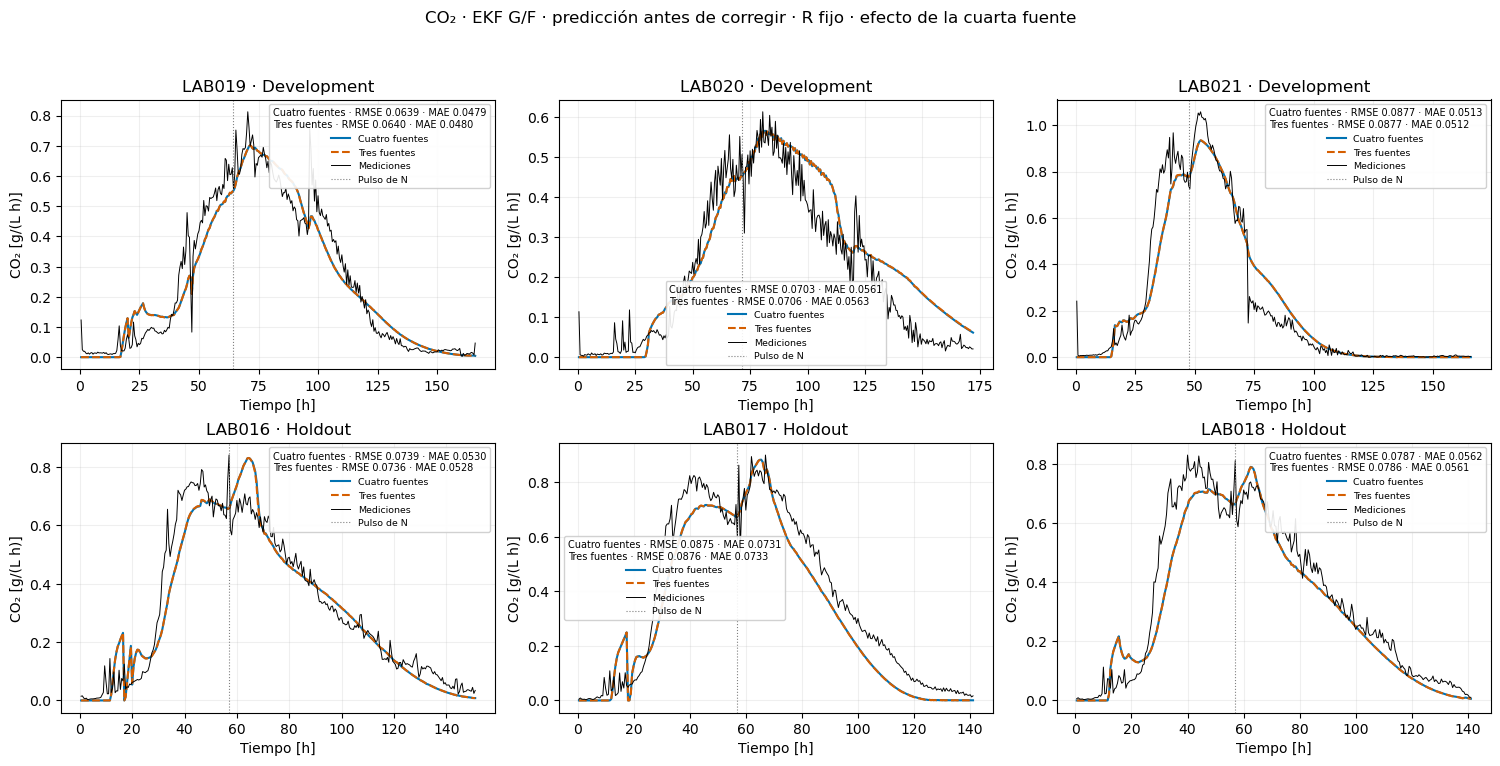

In [5]:
compare('CO2', 'CO₂')

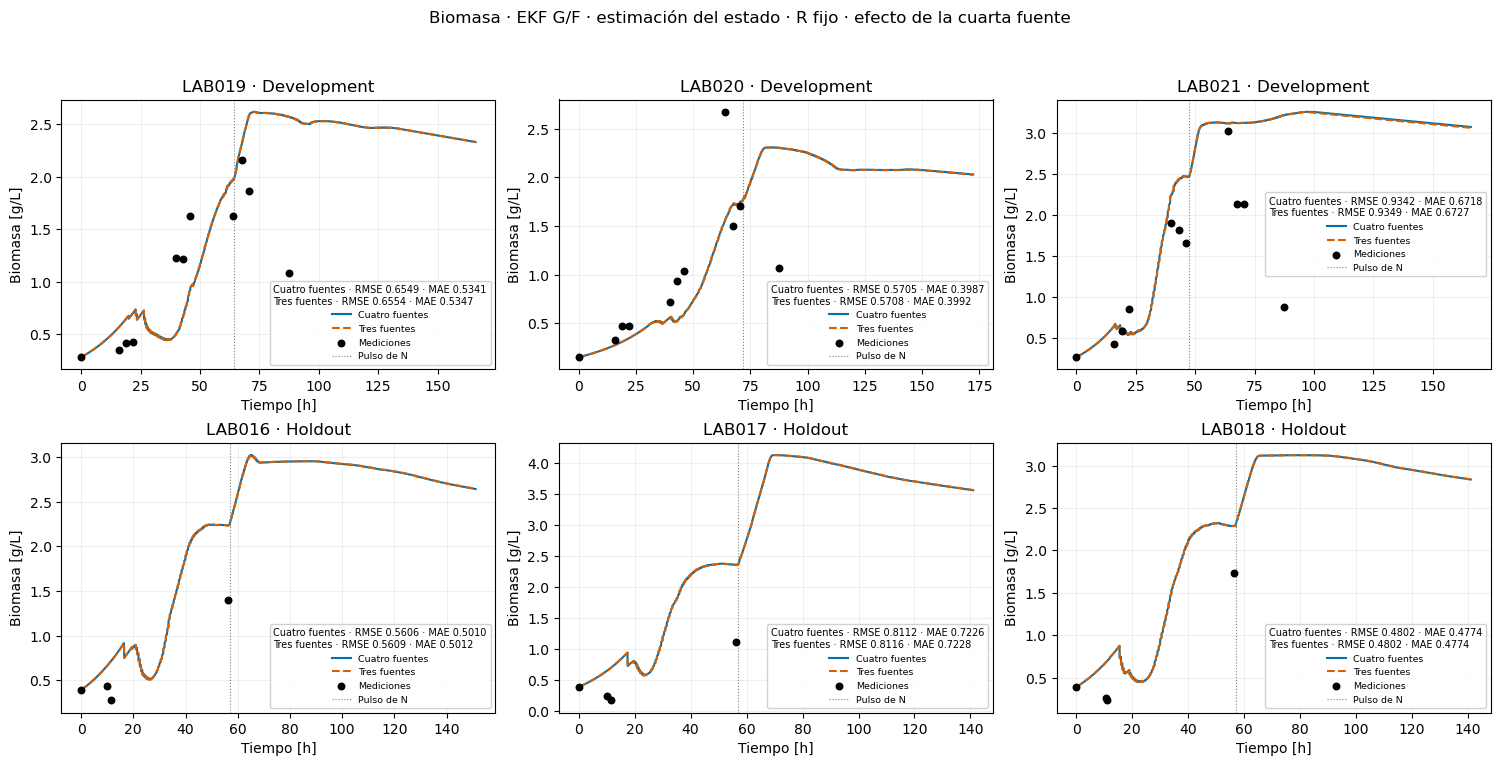

In [6]:
compare('X', 'Biomasa')

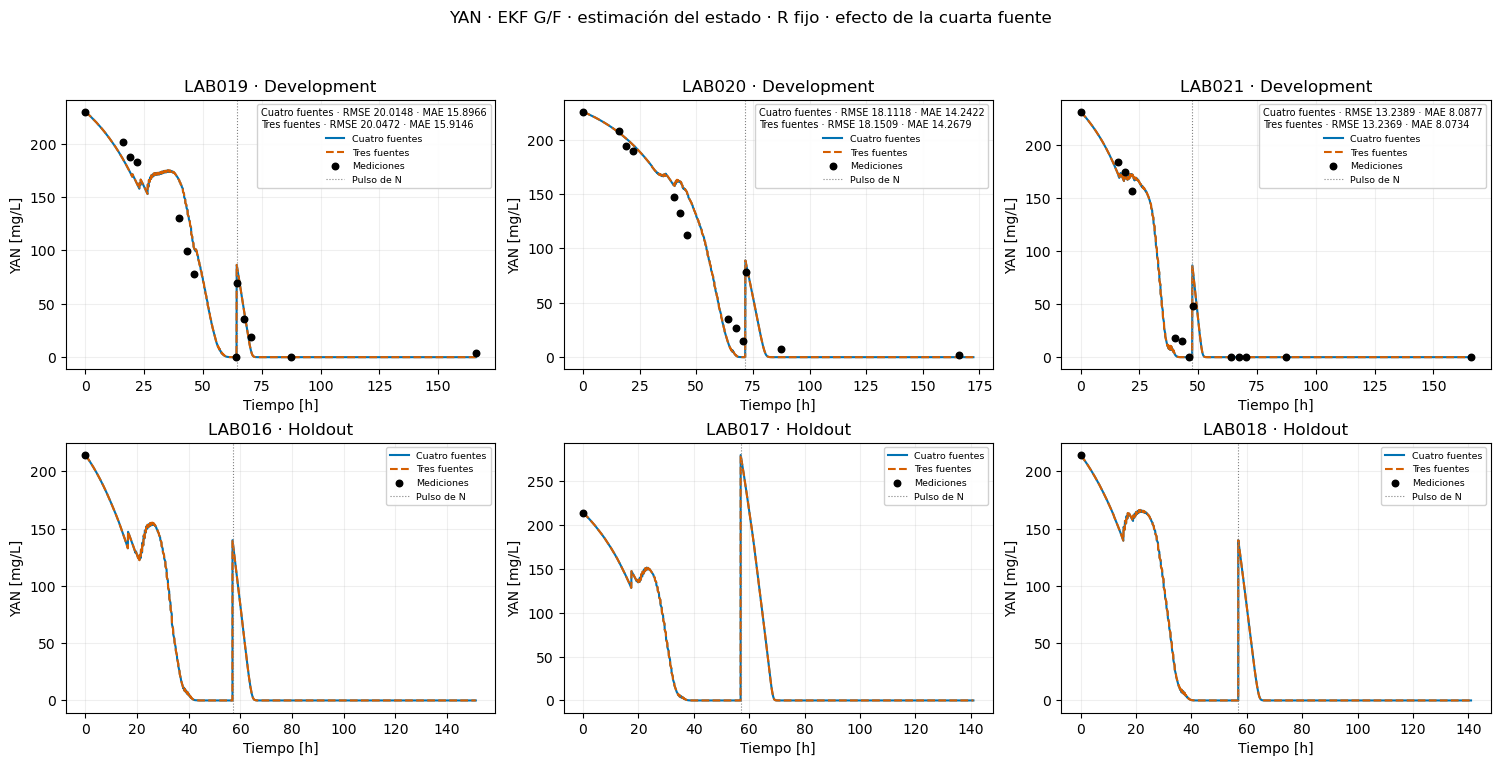

In [7]:
compare('N', 'YAN')

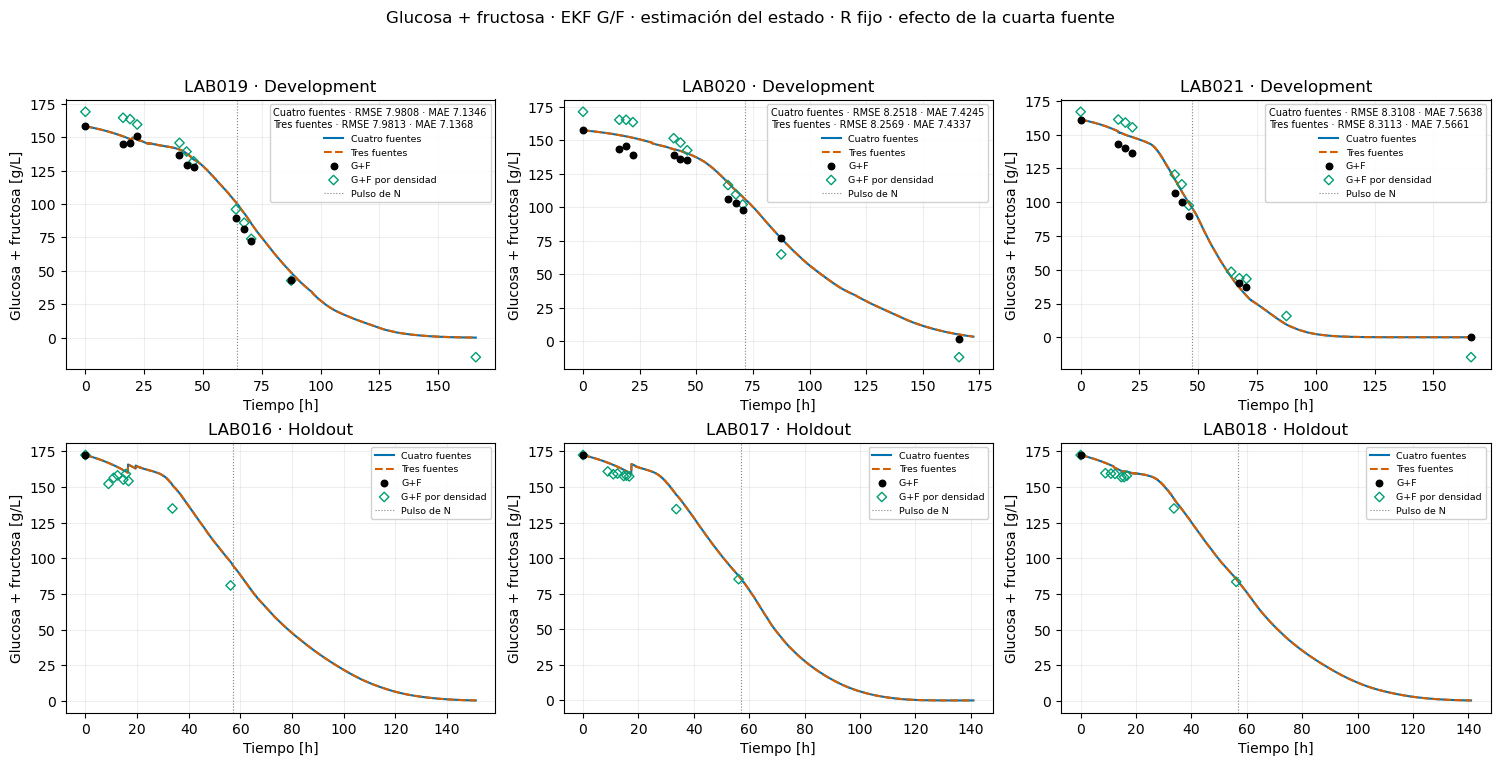

In [8]:
compare('GF', 'Glucosa + fructosa')

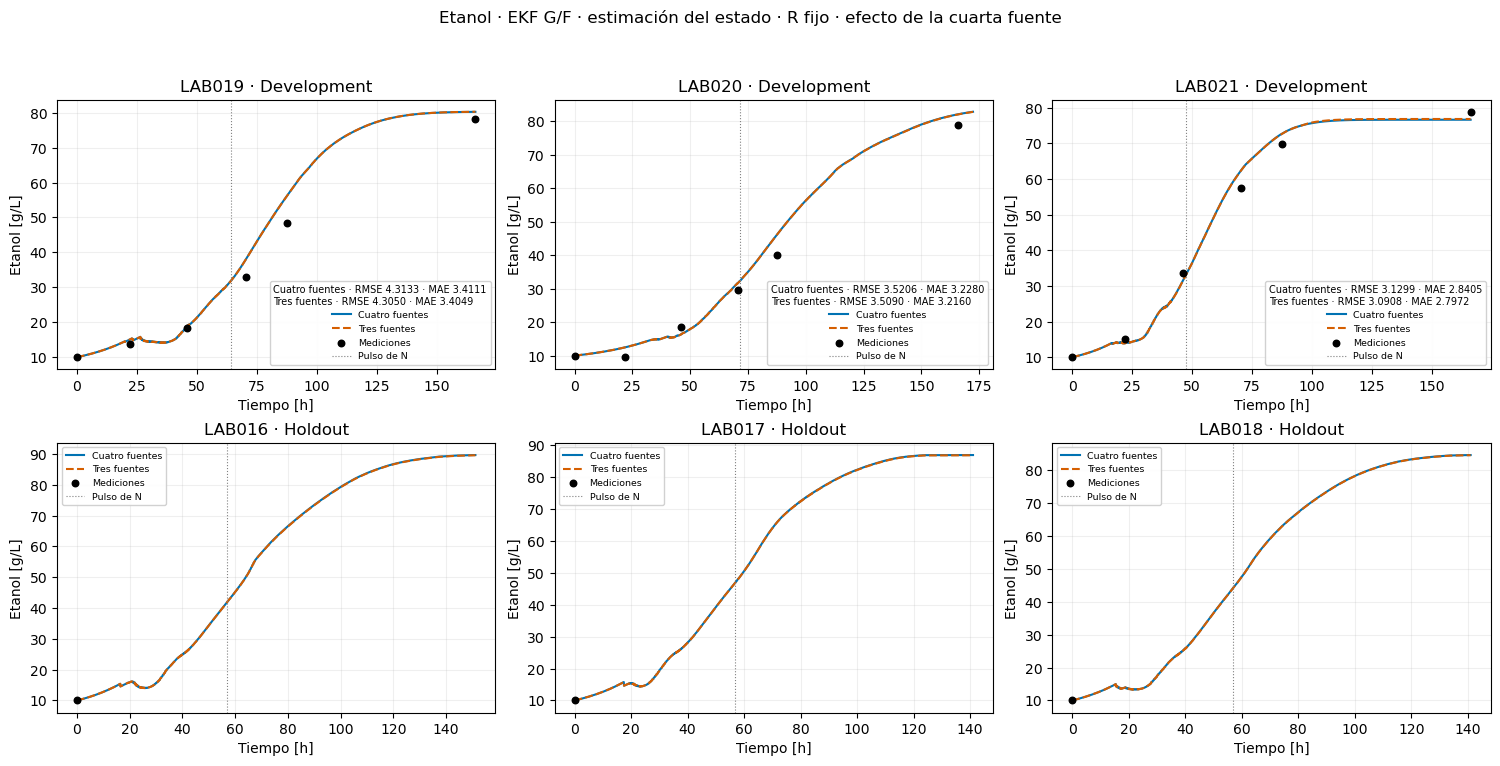

In [9]:
compare('E', 'Etanol')

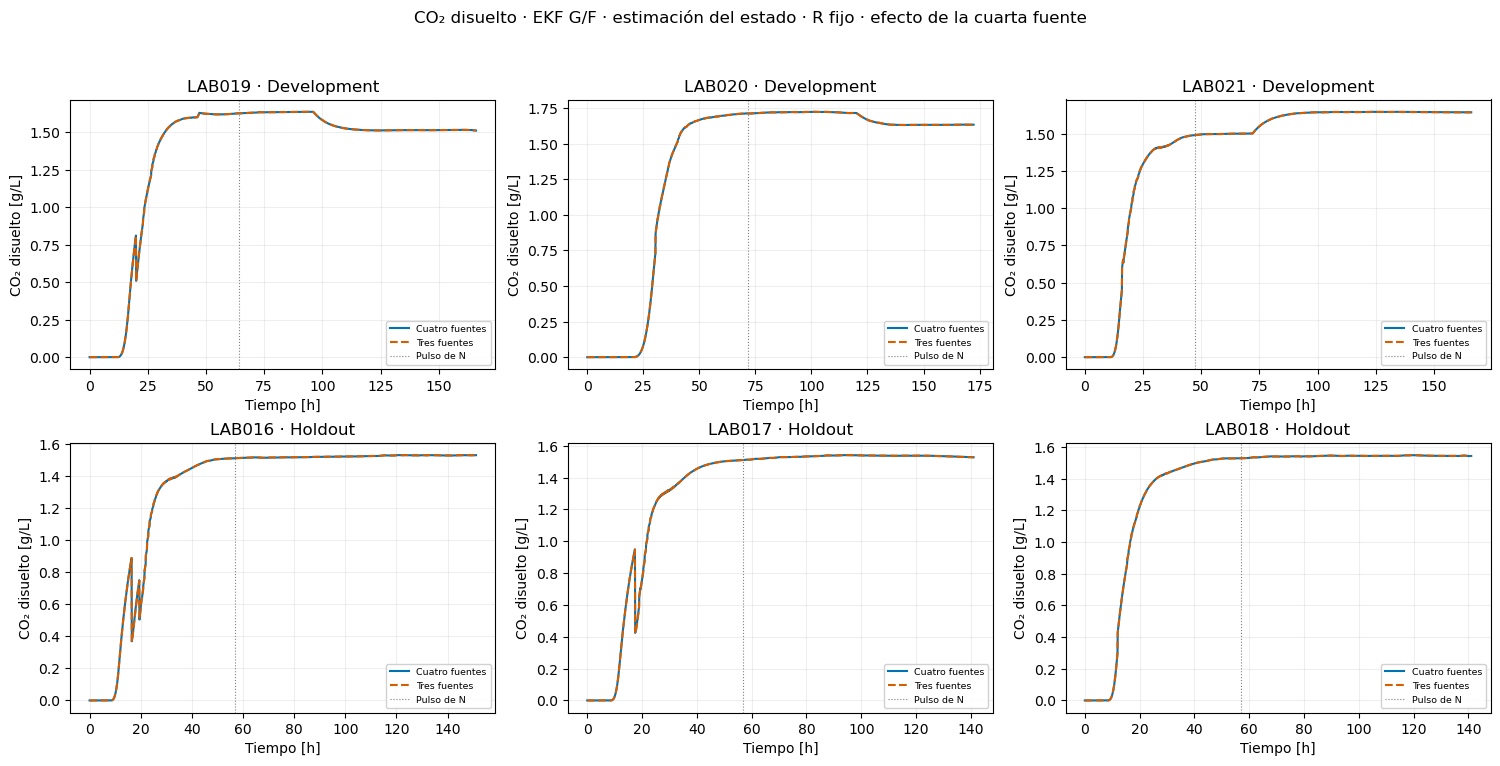

In [10]:
compare('Cd', 'CO₂ disuelto')

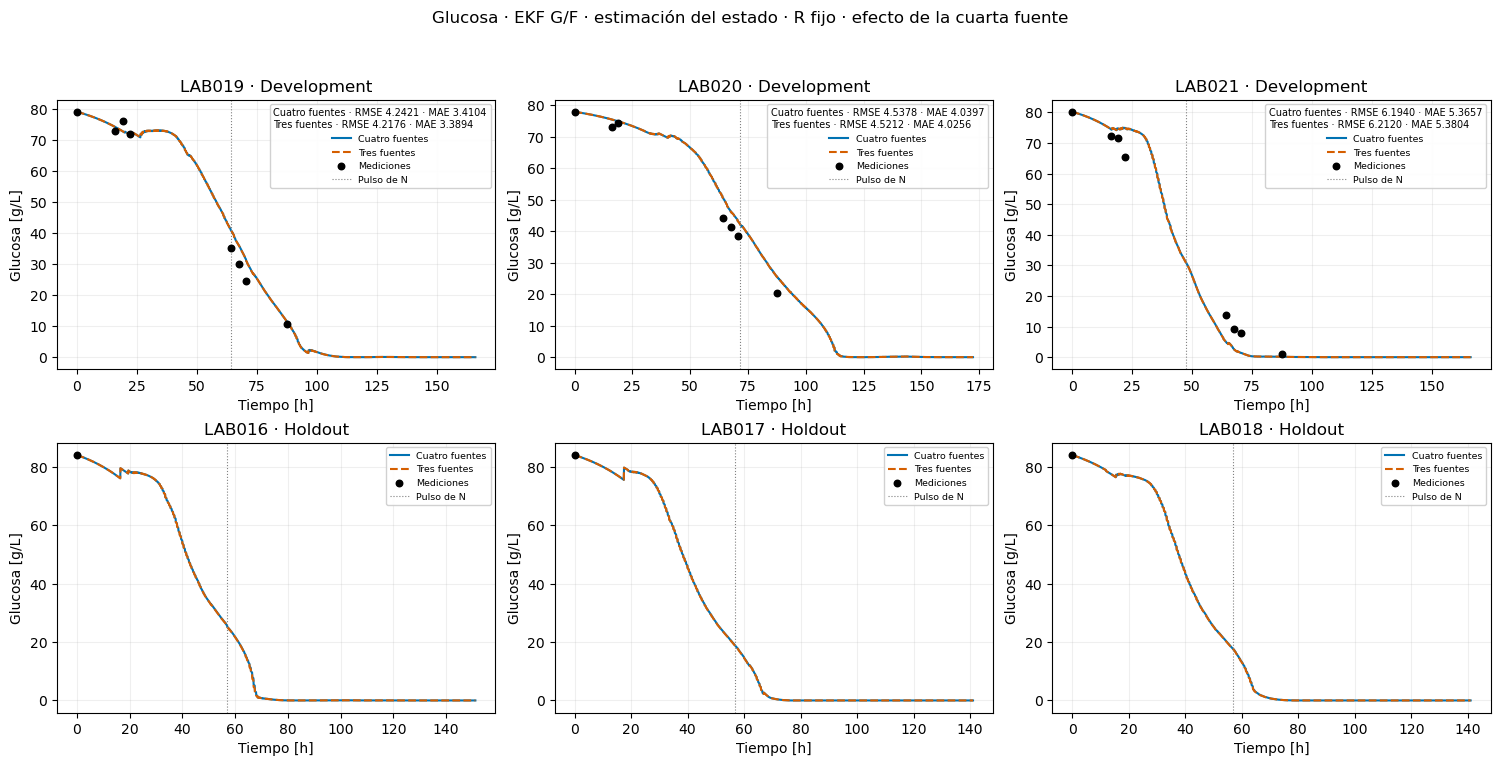

In [11]:
compare('G', 'Glucosa')

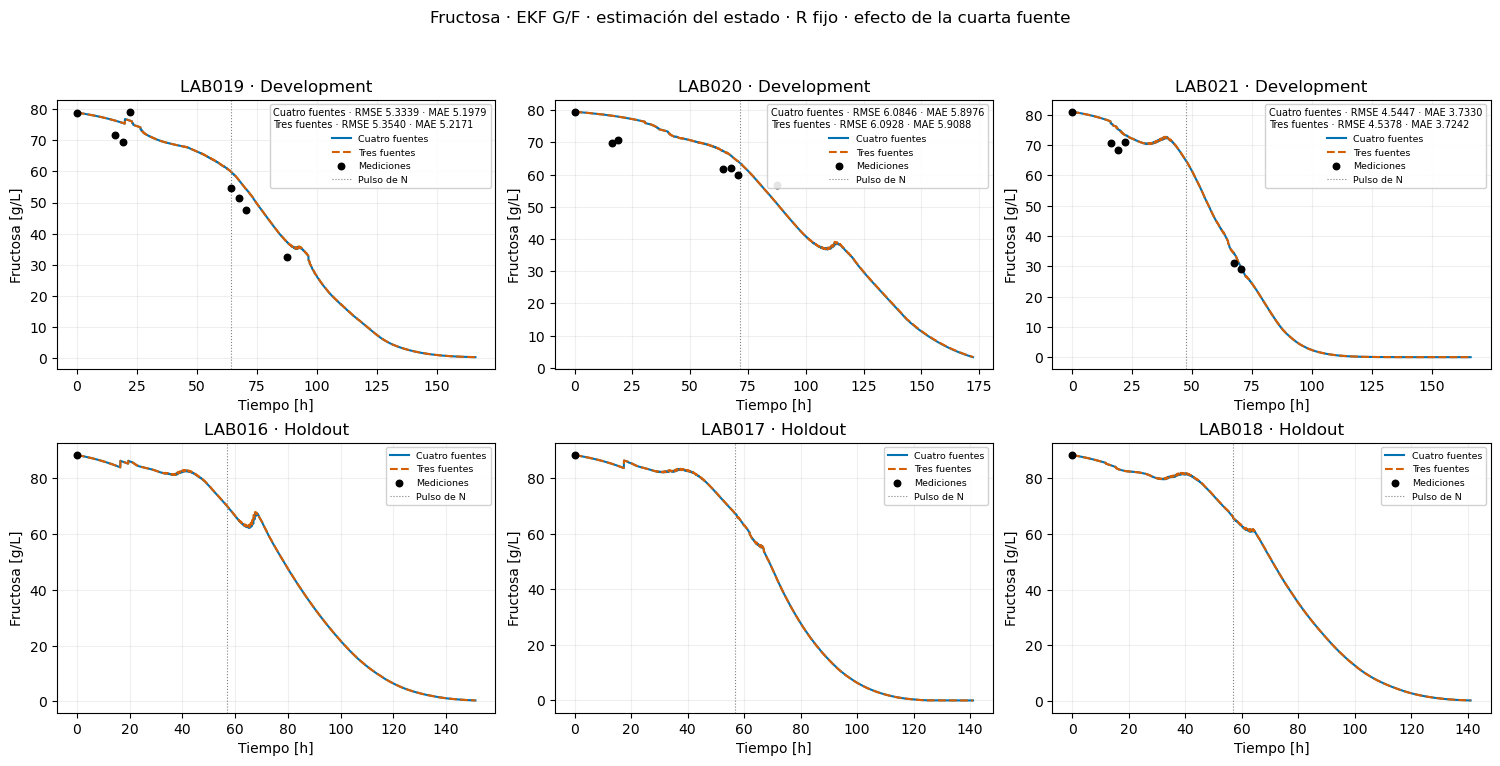

In [12]:
compare('F', 'Fructosa')

## Resultado de la comparación

Al quitar la cuarta fuente, el RMSE medio de CO₂ aumentó un 0,12 % en LAB019–021 y disminuyó un 0,12 % en LAB016–018. El MAE medio de CO₂ aumentó un 0,12 % en desarrollo y disminuyó un 0,09 % en validación. El cambio en el RMSE y el MAE medios de biomasa en validación fue inferior al 0,04 %. El mayor cambio absoluto entre los promedios por grupo fue del 0,65 %, en el MAE de etanol en desarrollo.

Las trayectorias casi se superponen. Los diagnósticos de innovación también fueron similares. El recorte de estados negativos pasó de 156 a 160 en LAB016 y de 24 a 25 en LAB021. Con las amplitudes heredadas del EKF 05, los seis lotes muestran poca sensibilidad a esta fuente. El resultado corresponde a la comparación con \(D_{44}=10^{-4}\) o \(D_{44}=0\) y \(R=0{,}00218\) fijo.

## Retiro de fuentes de crecimiento y fermentación

La referencia es el caso de tres fuentes activas. Se retira por turno una fuente para probar las tres parejas posibles. Luego se conserva una sola fuente por turno. El caso sin ruido de proceso sirve como referencia adicional en las tablas. En cada prueba, retirar una fuente equivale a poner su entrada diagonal de \(D\) en cero. Las fuentes activas usan las amplitudes históricas del EKF 05 y la medición usa \(R=0{,}00218\) fijo.

In [13]:
SOURCE_LABELS = ('Crecimiento', 'Fermentación de glucosa', 'Fermentación de fructosa')
PAIR_CASES = tuple(f'Sin {name.lower()}' for name in SOURCE_LABELS)
SINGLE_CASES = tuple(f'Solo {name.lower()}' for name in SOURCE_LABELS)
ZERO_CASE = 'Sin ruido de proceso'
source_cases = {
    **{case: tuple(j for j in range(3) if j != i) for i, case in enumerate(PAIR_CASES)},
    **{case: (i,) for i, case in enumerate(SINGLE_CASES)},
    ZERO_CASE: (),
}
amplitudes_by_case = {WITHOUT_SOURCE: three_sources}
for case, active in source_cases.items():
    amplitudes = np.zeros_like(three_sources)
    amplitudes[list(active)] = three_sources[list(active)]
    amplitudes_by_case[case] = amplitudes

display(pd.DataFrame(
    {case: amplitudes[:3]**2 for case, amplitudes in amplitudes_by_case.items()},
    index=SOURCE_LABELS,
).T.style.format('{:.2e}').set_caption('Entradas diagonales de D'))

extra_metrics, extra_checks = [], []
for case in source_cases:
    RESULTS[case] = {}
    for lab in LABS:
        data = DATA[lab]
        result = core.run(data, sigma=amplitudes_by_case[case], Rsd=np.sqrt(R))
        RESULTS[case][lab] = result
        metrics, info, _ = core.diagnostics(DATA, CHEM, lab, result)
        extra_metrics.append(metrics.assign(caso=case, grupo=ROLE[lab]))
        extra_checks.append(dict(info, caso=case, grupo=ROLE[lab]))
        np.testing.assert_array_equal(result[2][:, 5] == 1, data['update'])
        assert info['min_eigenvalue'] > -1e-7

ABLATION_CASES = [WITHOUT_SOURCE, *source_cases]
METRICS = pd.concat([METRICS, *extra_metrics], ignore_index=True)
ABLATION = METRICS.loc[METRICS.caso.isin(ABLATION_CASES)]
counts = ABLATION.pivot(index=keys, columns='caso', values='n')[ABLATION_CASES]
assert counts.eq(counts[WITHOUT_SOURCE], axis=0).all().all()

def ablation_table(metric, index):
    values = ABLATION.groupby(index + ['caso'])[metric].mean().unstack('caso')[ABLATION_CASES]
    return values, 100 * values.drop(columns=WITHOUT_SOURCE).div(values[WITHOUT_SOURCE], axis=0) - 100

for metric in ('RMSE', 'MAE'):
    means, change = ablation_table(metric, ['grupo', 'variable', 'unit'])
    display(means.style.format('{:.5f}').set_caption(f'{metric} medio por grupo'))
    display(change.style.format('{:+.2f}').set_caption(f'Cambio porcentual del {metric} respecto de tres fuentes'))
    by_lab, _ = ablation_table(metric, keys)
    display(by_lab.style.format('{:.5f}').set_caption(f'{metric} por lote'))

display(pd.DataFrame(extra_checks)[['grupo', 'LAB', 'caso', 'mean_NIS',
                                    'innovation_coverage95', 'lag1', 'clips']].round(4))


,Crecimiento,Fermentación de glucosa,Fermentación de fructosa
Tres fuentes,9.00e-06,6.40e-03,6.40e-03
Sin crecimiento,0.00e+00,6.40e-03,6.40e-03
Sin fermentación de glucosa,9.00e-06,0.00e+00,6.40e-03
Sin fermentación de fructosa,9.00e-06,6.40e-03,0.00e+00
Solo crecimiento,9.00e-06,0.00e+00,0.00e+00
Solo fermentación de glucosa,0.00e+00,6.40e-03,0.00e+00
Solo fermentación de fructosa,0.00e+00,0.00e+00,6.40e-03
Sin ruido de proceso,0.00e+00,0.00e+00,0.00e+00


,grupo,LAB,caso,mean_NIS,innovation_coverage95,lag1,clips
0,Development,LAB019,Sin crecimiento,1.2055,0.9493,0.8070,16
1,Development,LAB020,Sin crecimiento,1.1519,0.9507,0.7348,24
2,Development,LAB021,Sin crecimiento,3.1506,0.7530,0.9177,40
3,Holdout,LAB016,Sin crecimiento,1.2216,0.9036,0.8670,111
4,Holdout,LAB017,Sin crecimiento,1.9328,0.9014,0.8020,187
5,Holdout,LAB018,Sin crecimiento,1.4205,0.9030,0.8847,184
6,Development,LAB019,Sin fermentación de glucosa,1.6179,0.9032,0.8104,43
7,Development,LAB020,Sin fermentación de glucosa,1.3205,0.9058,0.7060,12
8,Development,LAB021,Sin fermentación de glucosa,3.6740,0.7470,0.9074,22
9,Holdout,LAB016,Sin fermentación de glucosa,1.3911,0.8956,0.8545,83


## Aporte directo de cada fuente a la diagonal de \(Q\)

Para comparar las magnitudes de las perturbaciones en el mismo estado, evaluamos \(L_k\) sobre la trayectoria de referencia con tres fuentes. Para cada estado \(i\) sumamos en el tiempo \(\Delta t_k L_{k,ij}^2 D_{jj}\) por fuente \(j\). La tabla expresa cada aporte como porcentaje del total para ese estado. Esta suma cuantifica la varianza que se inyecta directamente en cada paso. El efecto en las predicciones también depende de cómo el EKF propaga esa incertidumbre entre estados y corrige con las observaciones.

In [14]:
kla, gain = core.ARCHIVED_GAS
contributions = []
for lab in LABS:
    data = DATA[lab]
    trajectory = RESULTS[WITHOUT_SOURCE][lab][0]
    grid = data['grid']
    totals = np.zeros((len(core.STATES), 3))
    for k, dt in enumerate(np.diff(grid)):
        temperature = core.temperature_at(grid[k], data['available'], data['temperature'])
        L = core.noise_L(trajectory[k], temperature, data['S0'], kla, gain)
        totals += dt * L[:, :3]**2 * three_sources[:3]**2
    totals = pd.DataFrame(totals, index=pd.Index(core.STATES, name='Estado'), columns=SOURCE_LABELS)
    contributions.append(totals.assign(LAB=lab, grupo=ROLE[lab]).reset_index())

injected = pd.concat(contributions, ignore_index=True)
for index, title in [(['grupo', 'Estado'], 'por grupo'), (['LAB', 'Estado'], 'por lote')]:
    totals = injected.groupby(index)[list(SOURCE_LABELS)].sum()
    shares = 100 * totals.div(totals.sum(axis=1), axis=0)
    display(shares.style.format('{:.2f}', na_rep='—').set_caption(f'Aporte directo a la varianza de cada estado (%), {title}'))


## Trayectorias de las combinaciones de dos fuentes

Cada figura superpone las tres parejas y la referencia de tres fuentes.

In [15]:
source_colors = ('#D55E00', '#009E73', '#CC79A7')
source_styles = ('--', '-.', ':')
COLORS.update(dict(zip(PAIR_CASES, source_colors)))
COLORS.update(dict(zip(SINGLE_CASES, source_colors)))
STYLES.update(dict(zip(PAIR_CASES, source_styles)))
STYLES.update(dict(zip(SINGLE_CASES, source_styles)))
COLORS[WITHOUT_SOURCE], STYLES[WITHOUT_SOURCE] = '#0072B2', '-'


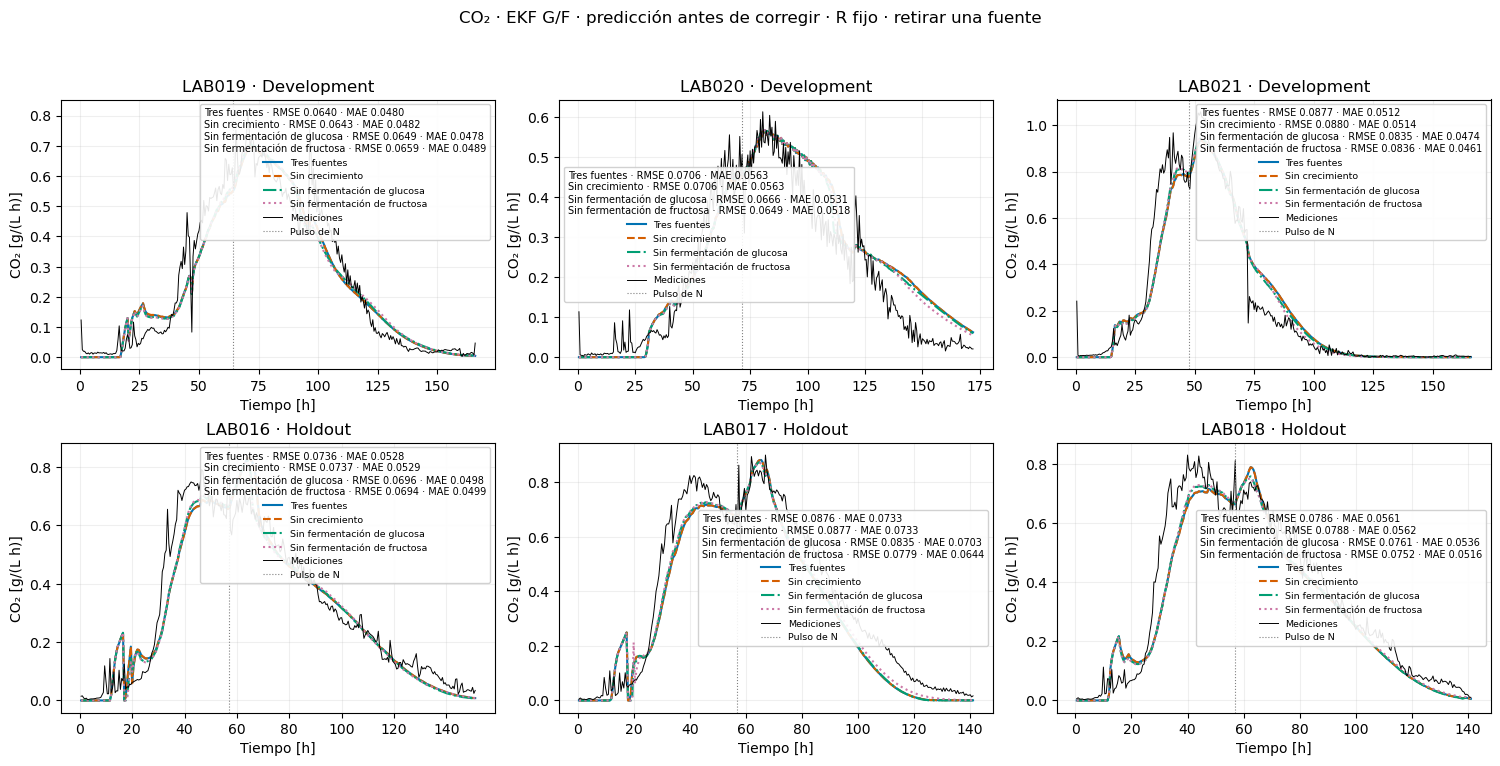

In [16]:
compare('CO2', 'CO₂', cases=(WITHOUT_SOURCE, *PAIR_CASES), comparison='retirar una fuente')

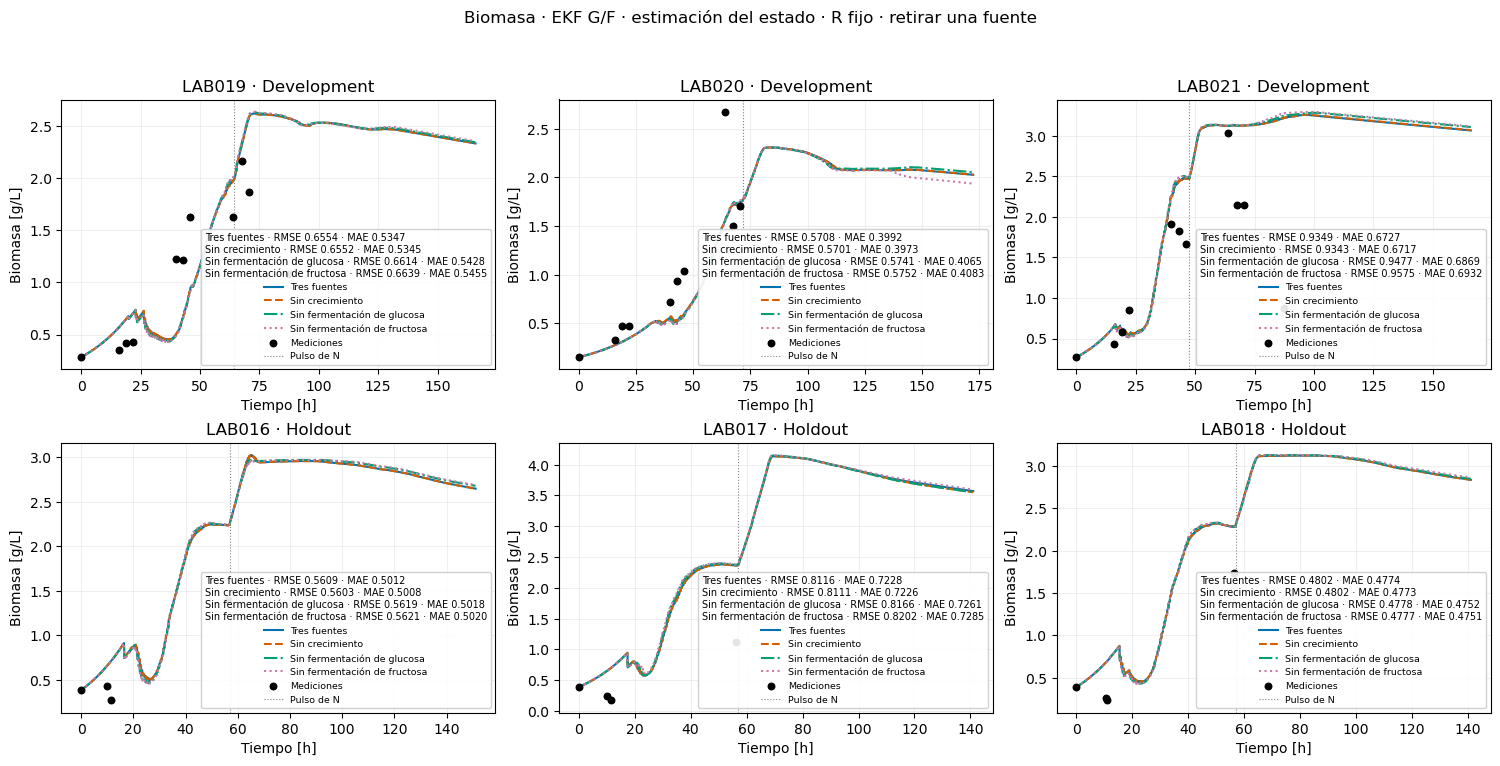

In [17]:
compare('X', 'Biomasa', cases=(WITHOUT_SOURCE, *PAIR_CASES), comparison='retirar una fuente')

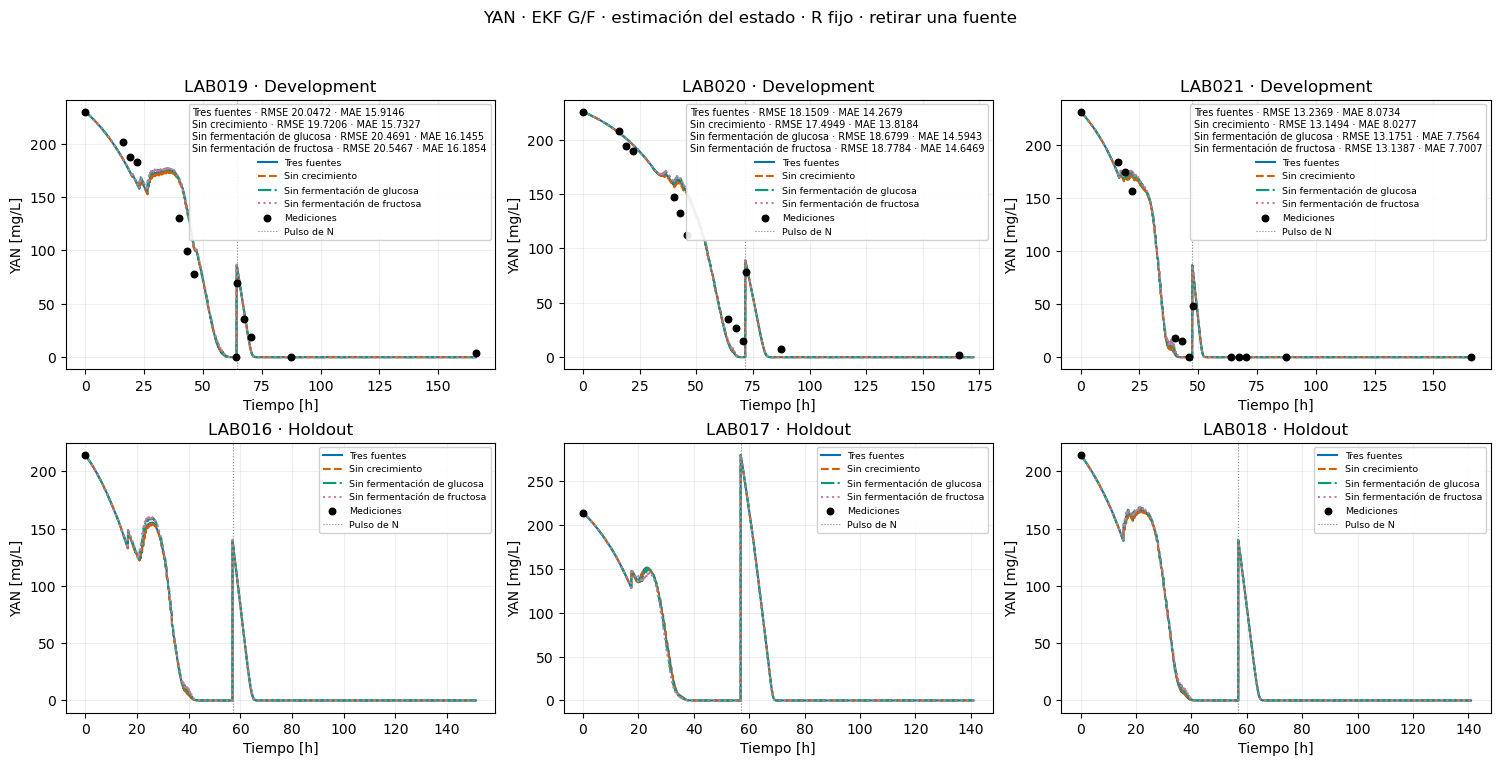

In [18]:
compare('N', 'YAN', cases=(WITHOUT_SOURCE, *PAIR_CASES), comparison='retirar una fuente')

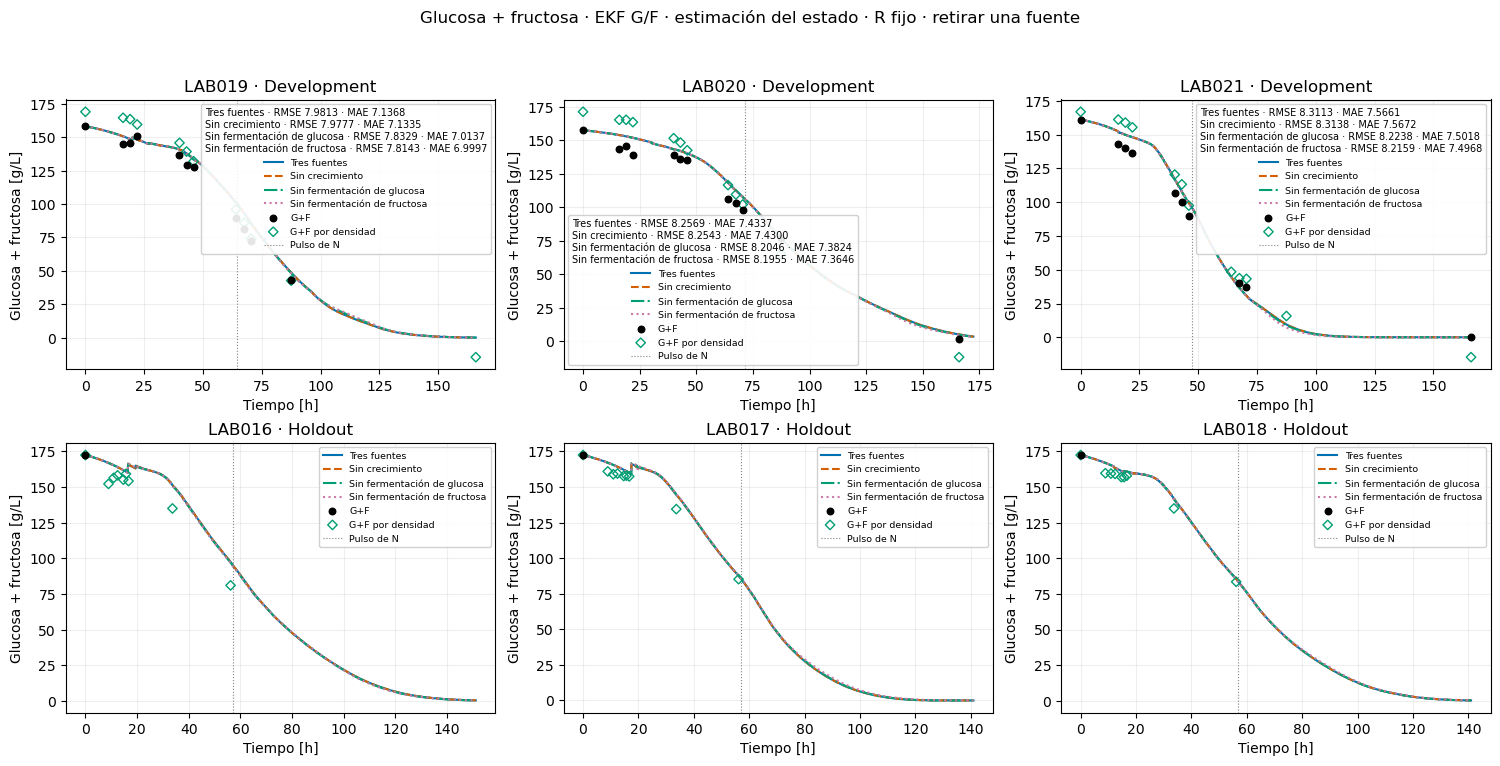

In [19]:
compare('GF', 'Glucosa + fructosa', cases=(WITHOUT_SOURCE, *PAIR_CASES), comparison='retirar una fuente')

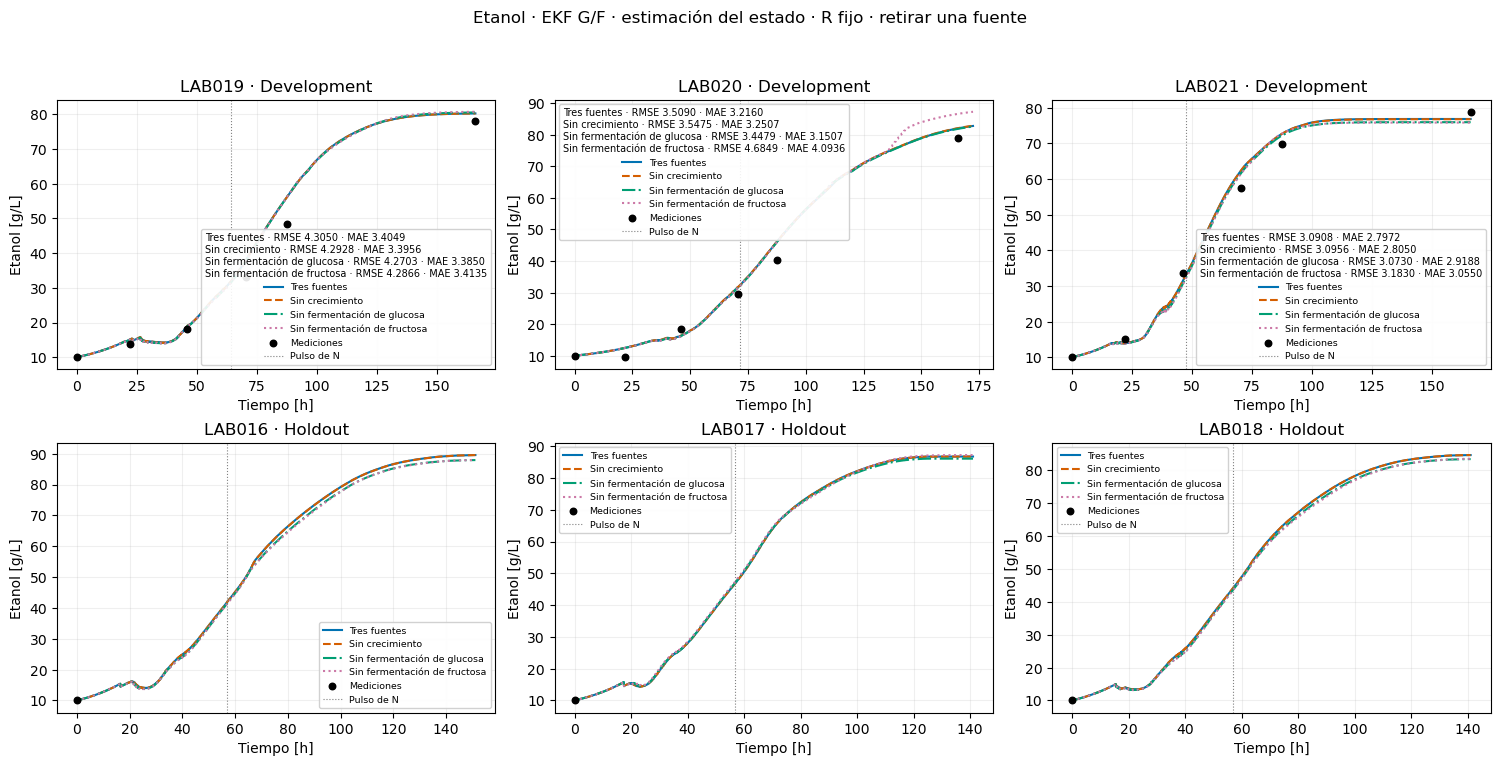

In [20]:
compare('E', 'Etanol', cases=(WITHOUT_SOURCE, *PAIR_CASES), comparison='retirar una fuente')

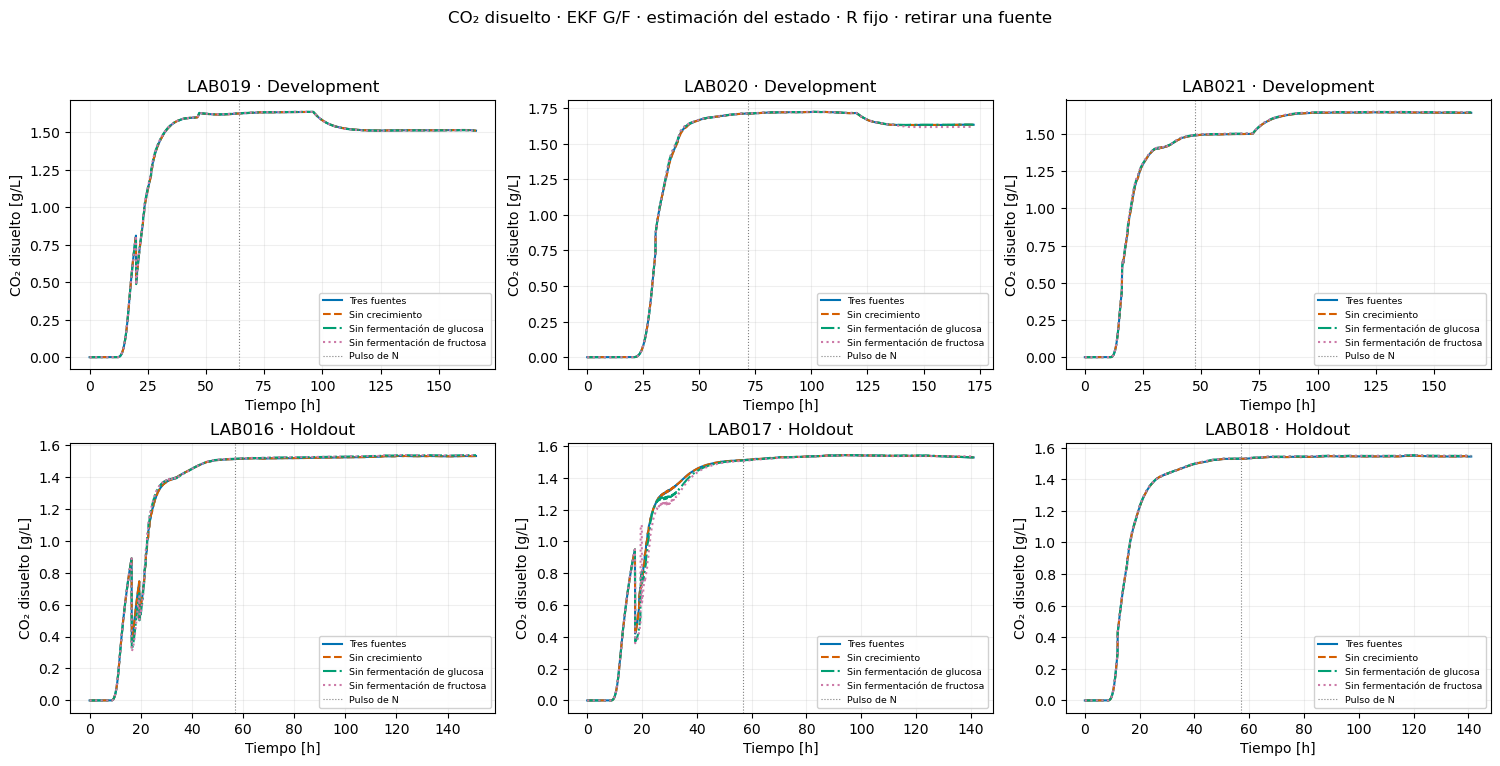

In [21]:
compare('Cd', 'CO₂ disuelto', cases=(WITHOUT_SOURCE, *PAIR_CASES), comparison='retirar una fuente')

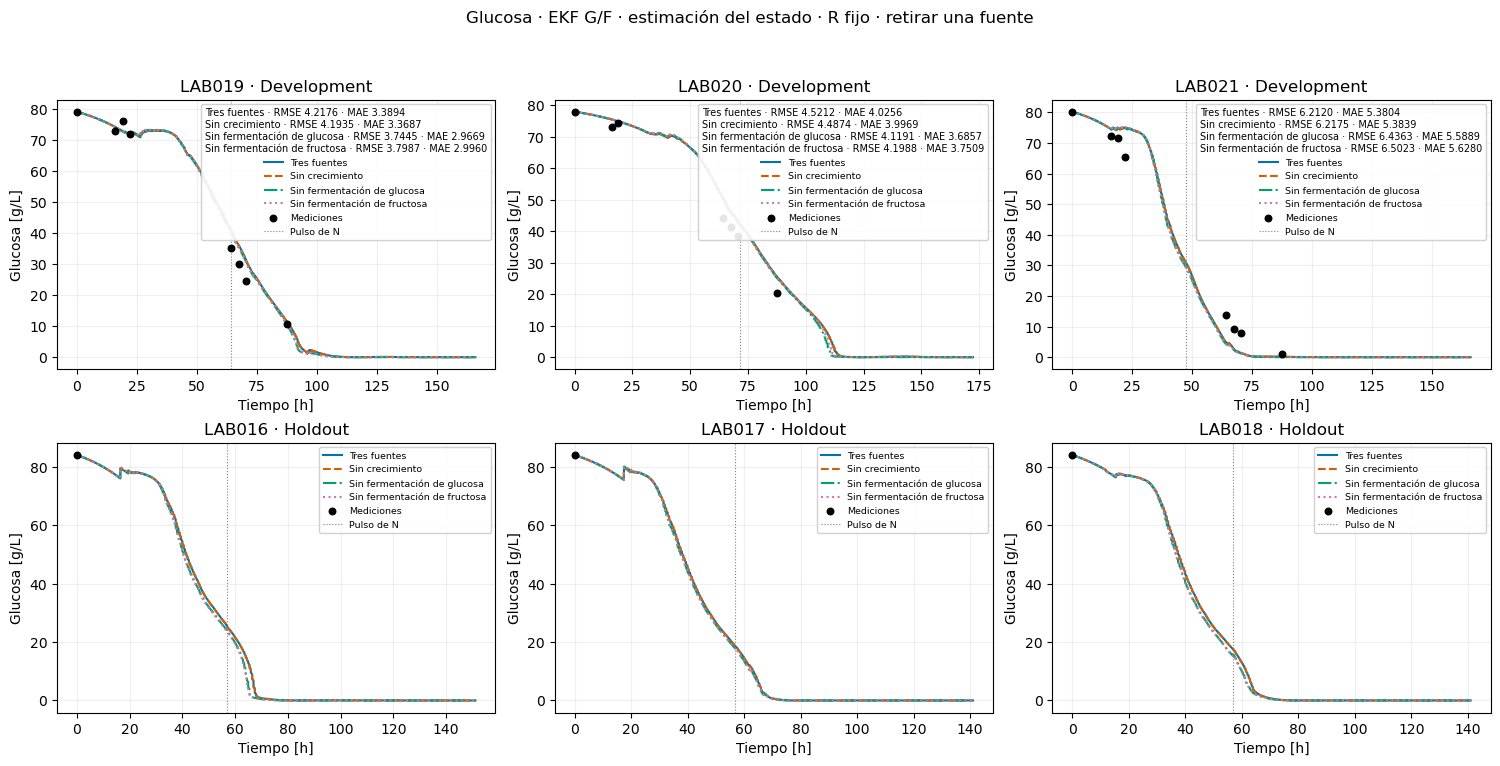

In [22]:
compare('G', 'Glucosa', cases=(WITHOUT_SOURCE, *PAIR_CASES), comparison='retirar una fuente')

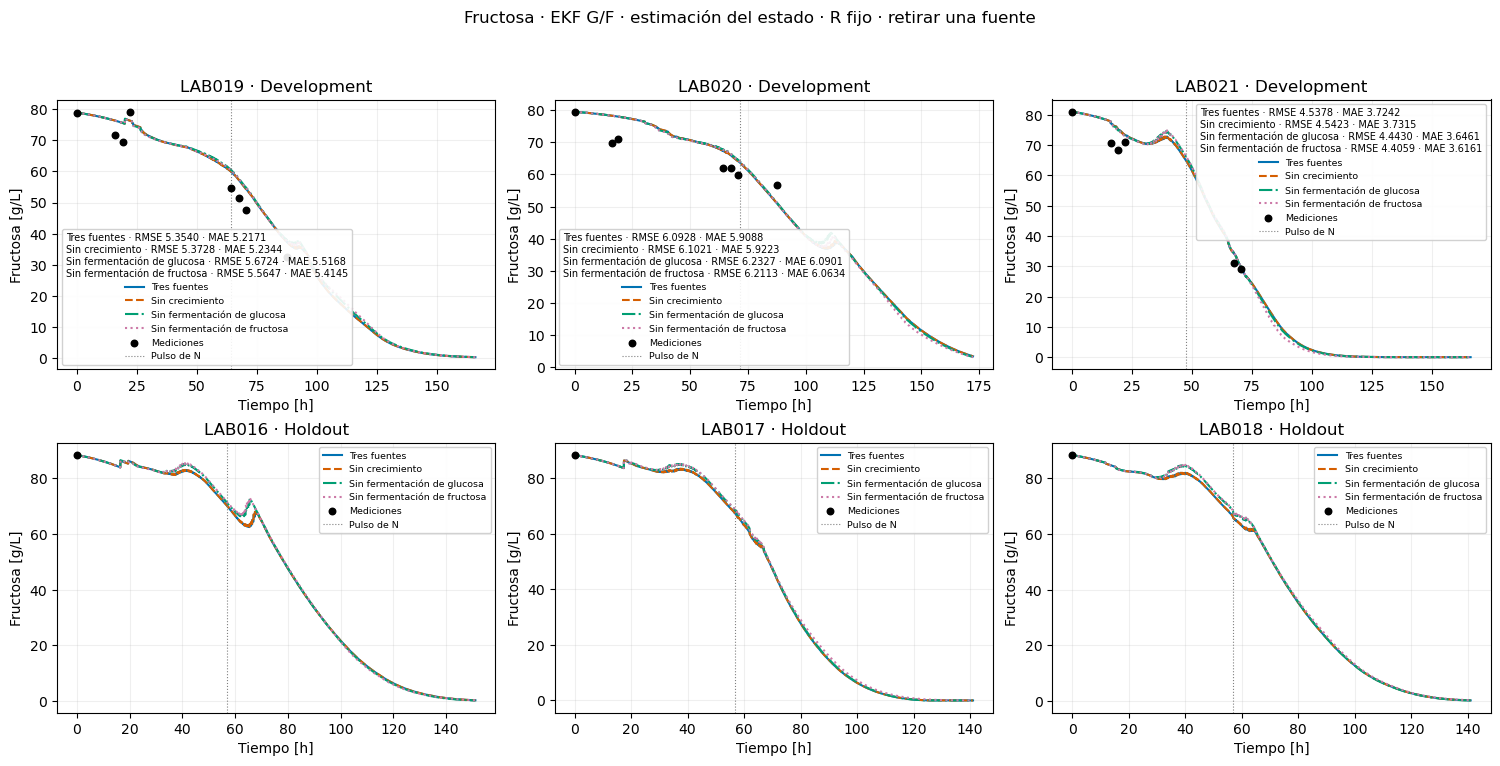

In [23]:
compare('F', 'Fructosa', cases=(WITHOUT_SOURCE, *PAIR_CASES), comparison='retirar una fuente')

## Trayectorias con una sola fuente

Cada figura superpone las tres fuentes por separado y la referencia de tres fuentes.

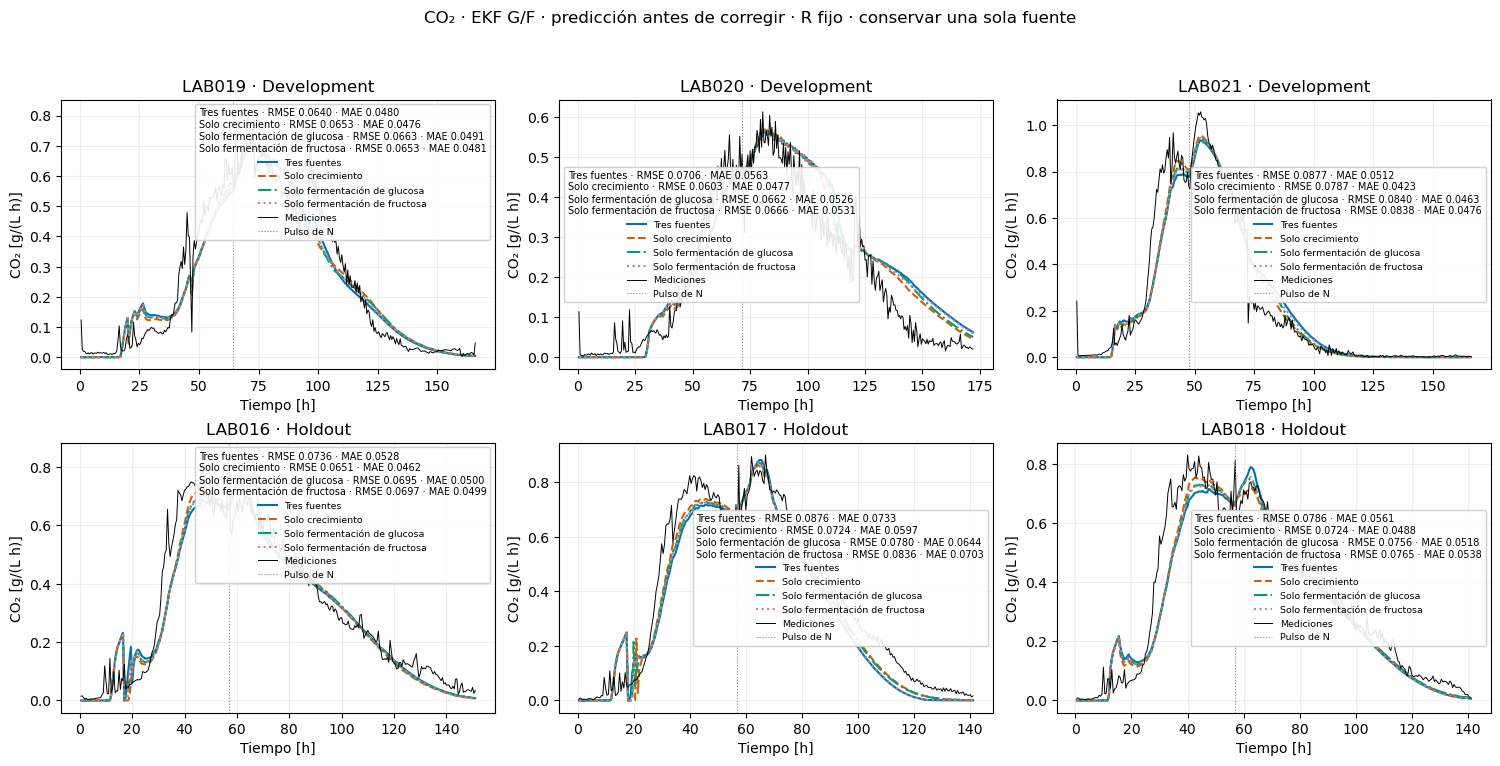

In [24]:
compare('CO2', 'CO₂', cases=(WITHOUT_SOURCE, *SINGLE_CASES), comparison='conservar una sola fuente')

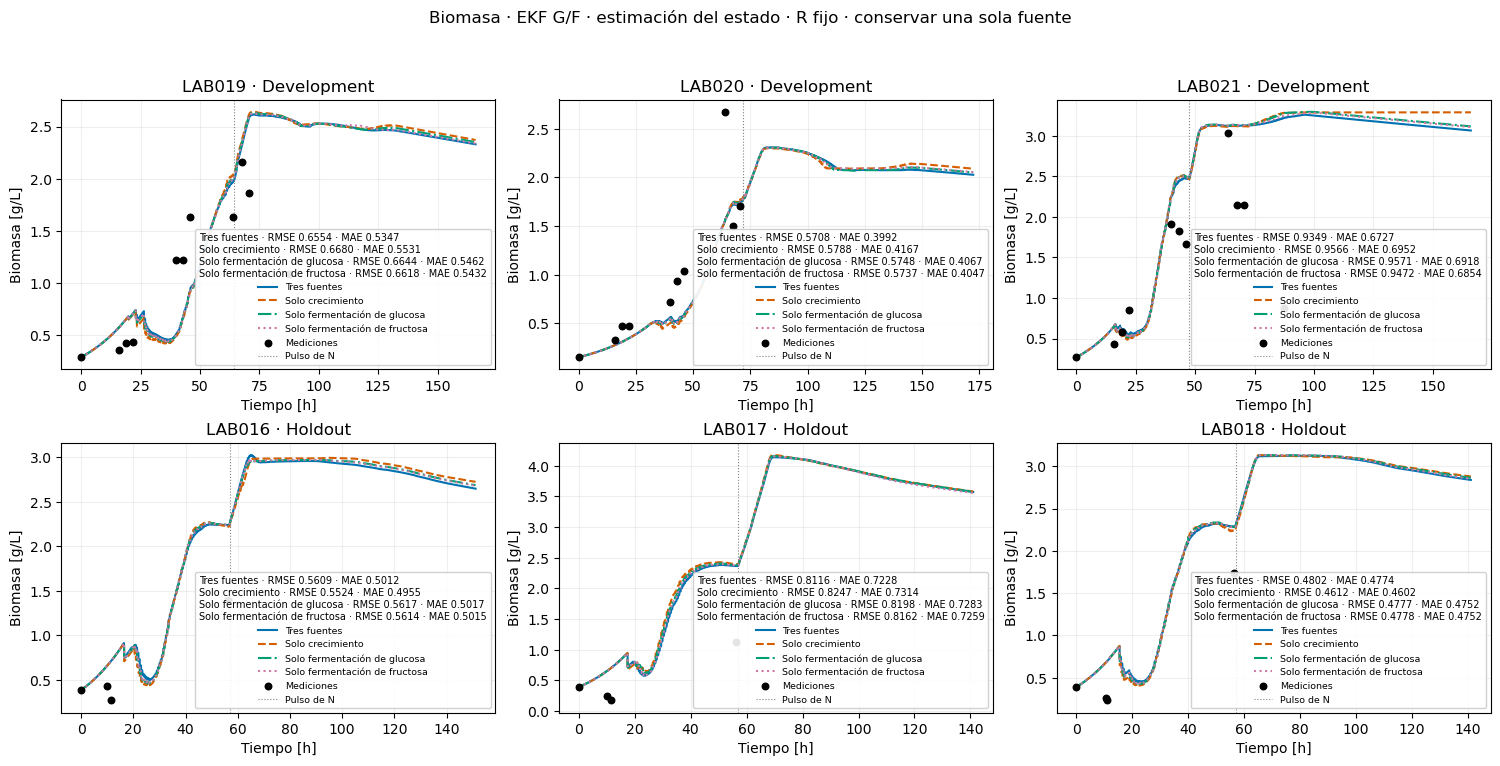

In [25]:
compare('X', 'Biomasa', cases=(WITHOUT_SOURCE, *SINGLE_CASES), comparison='conservar una sola fuente')

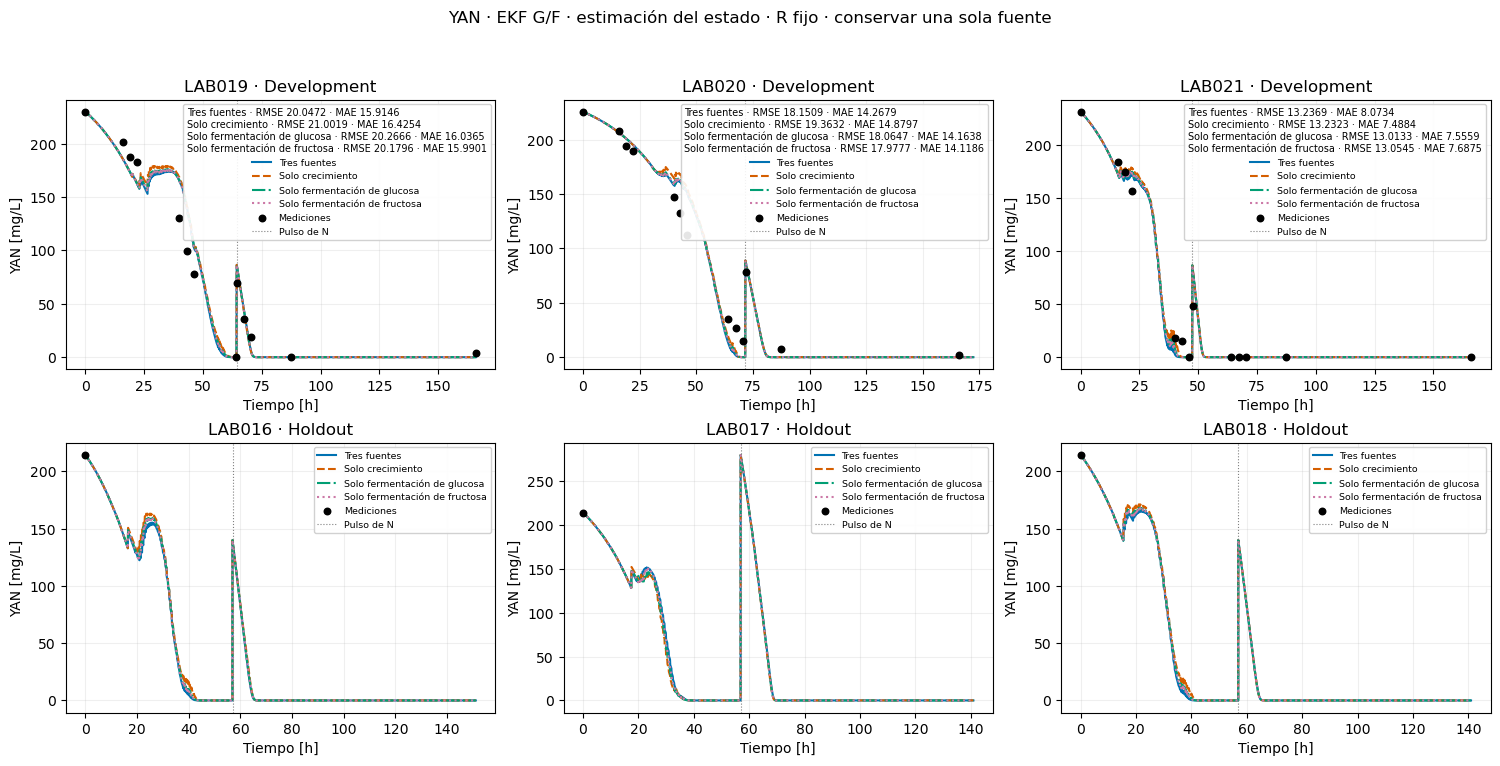

In [26]:
compare('N', 'YAN', cases=(WITHOUT_SOURCE, *SINGLE_CASES), comparison='conservar una sola fuente')

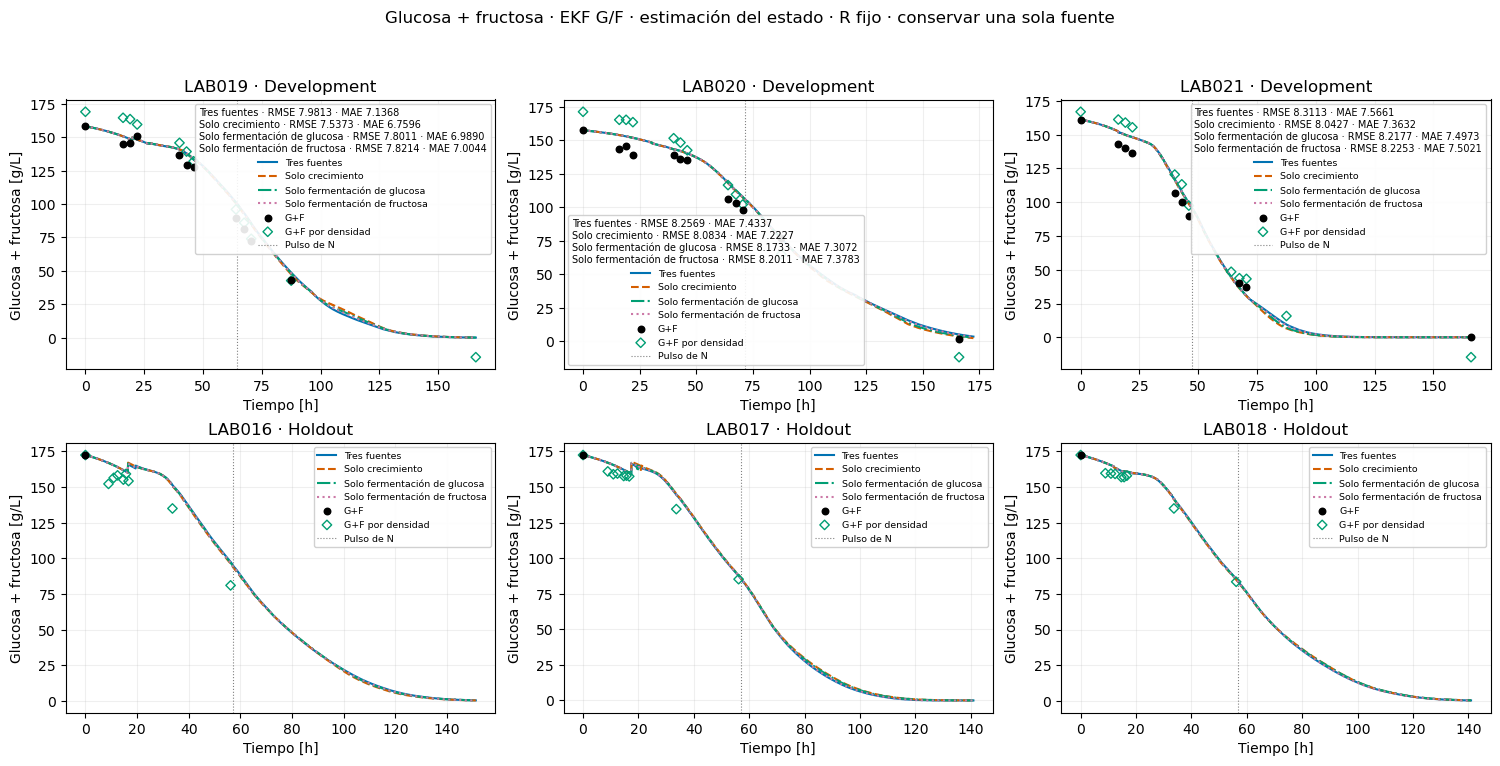

In [27]:
compare('GF', 'Glucosa + fructosa', cases=(WITHOUT_SOURCE, *SINGLE_CASES), comparison='conservar una sola fuente')

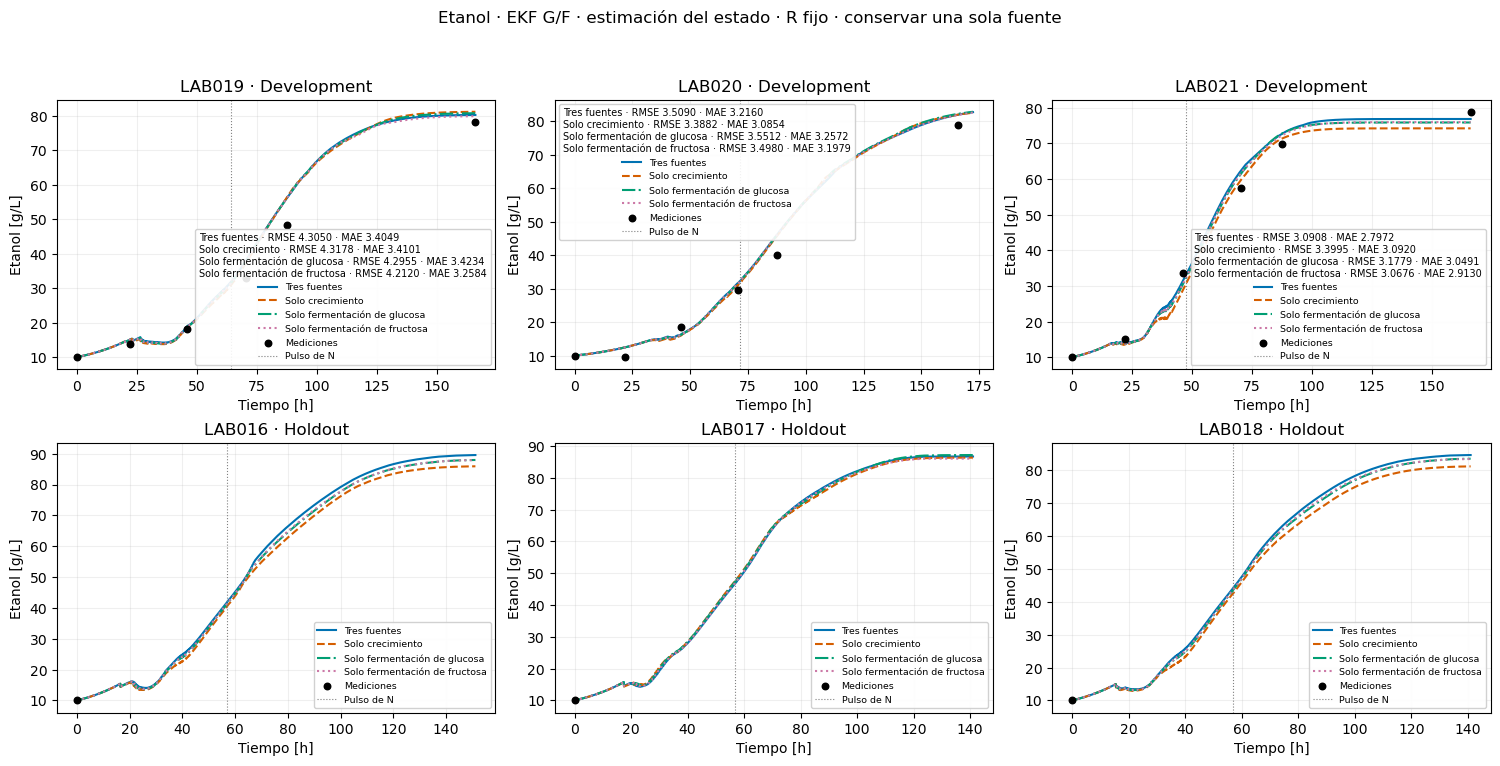

In [28]:
compare('E', 'Etanol', cases=(WITHOUT_SOURCE, *SINGLE_CASES), comparison='conservar una sola fuente')

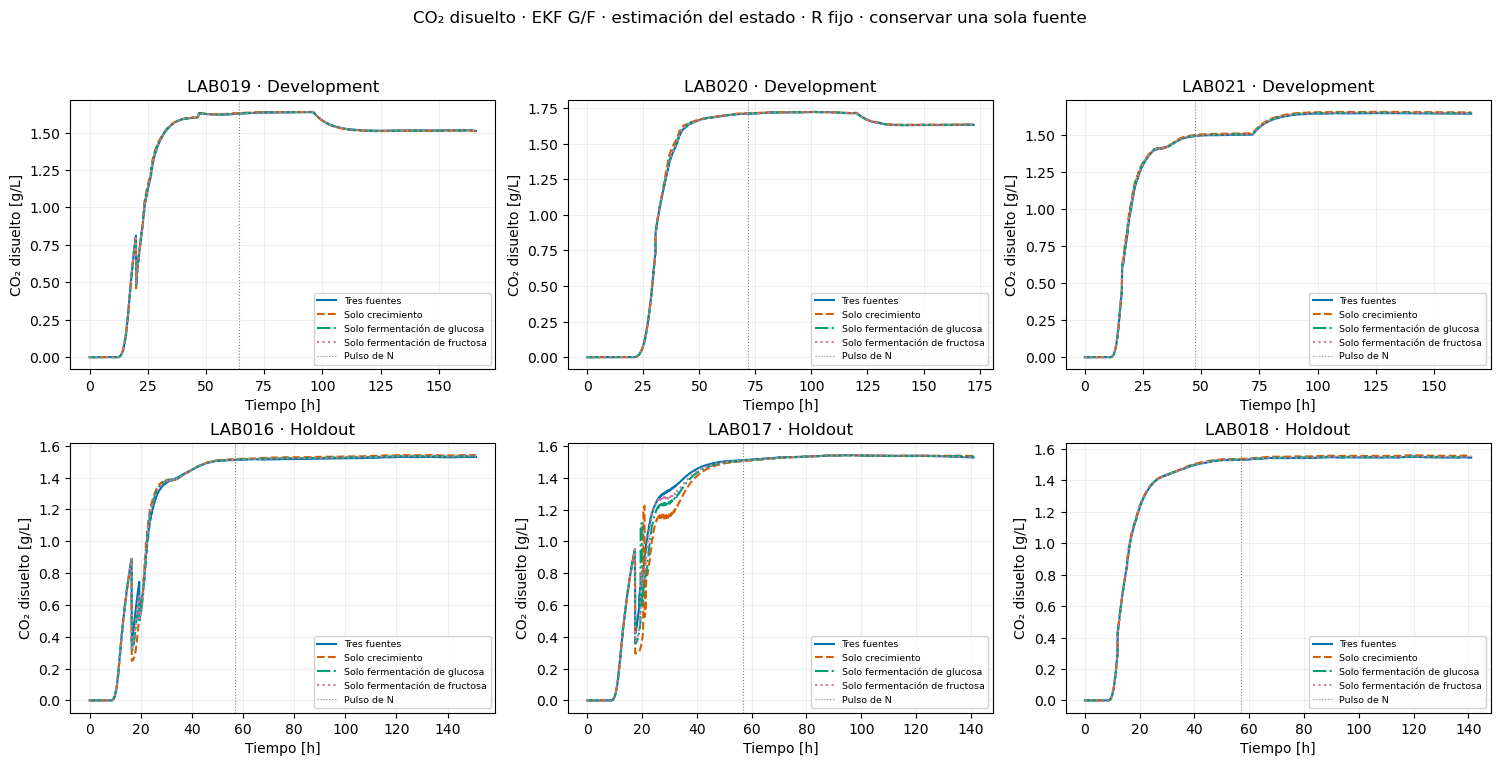

In [29]:
compare('Cd', 'CO₂ disuelto', cases=(WITHOUT_SOURCE, *SINGLE_CASES), comparison='conservar una sola fuente')

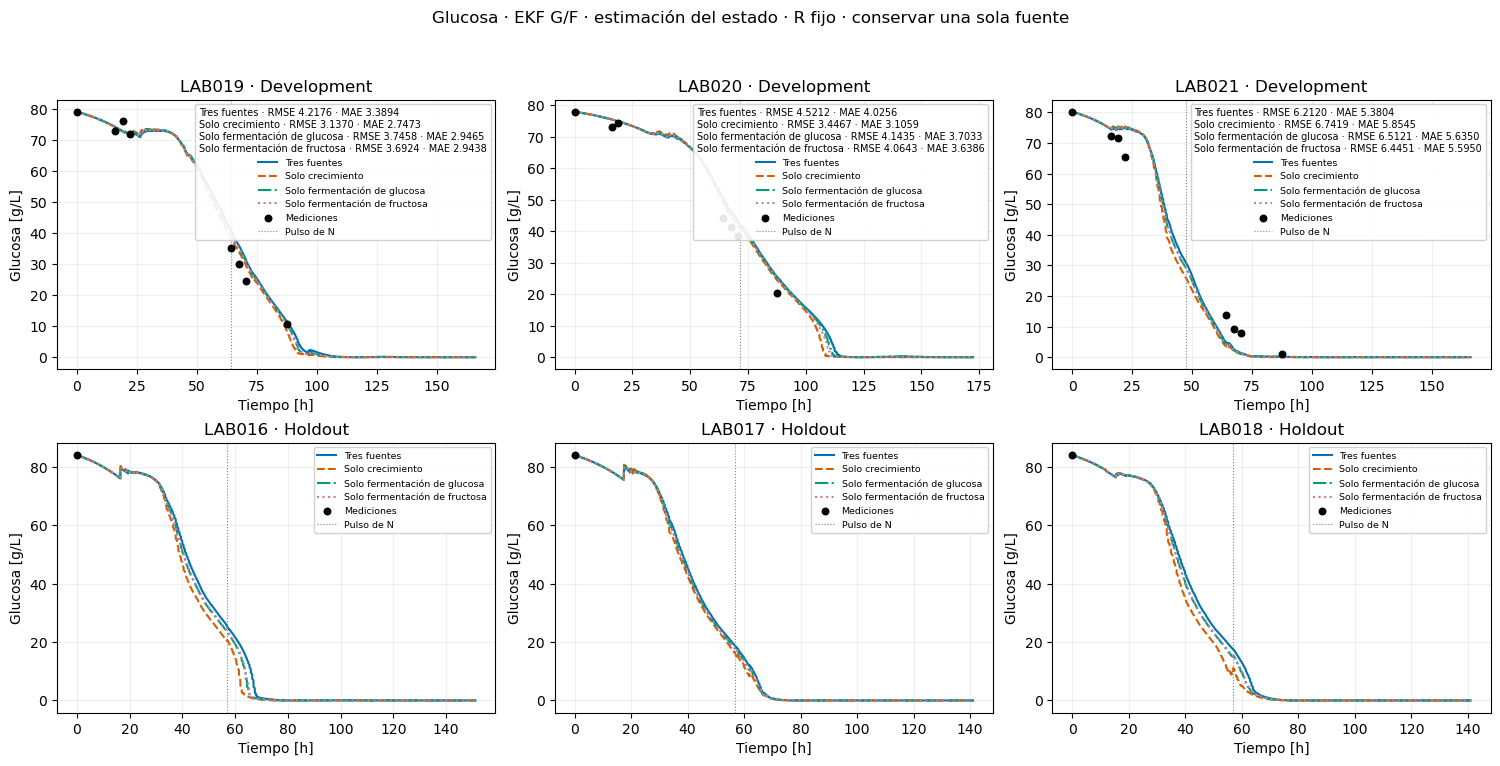

In [30]:
compare('G', 'Glucosa', cases=(WITHOUT_SOURCE, *SINGLE_CASES), comparison='conservar una sola fuente')

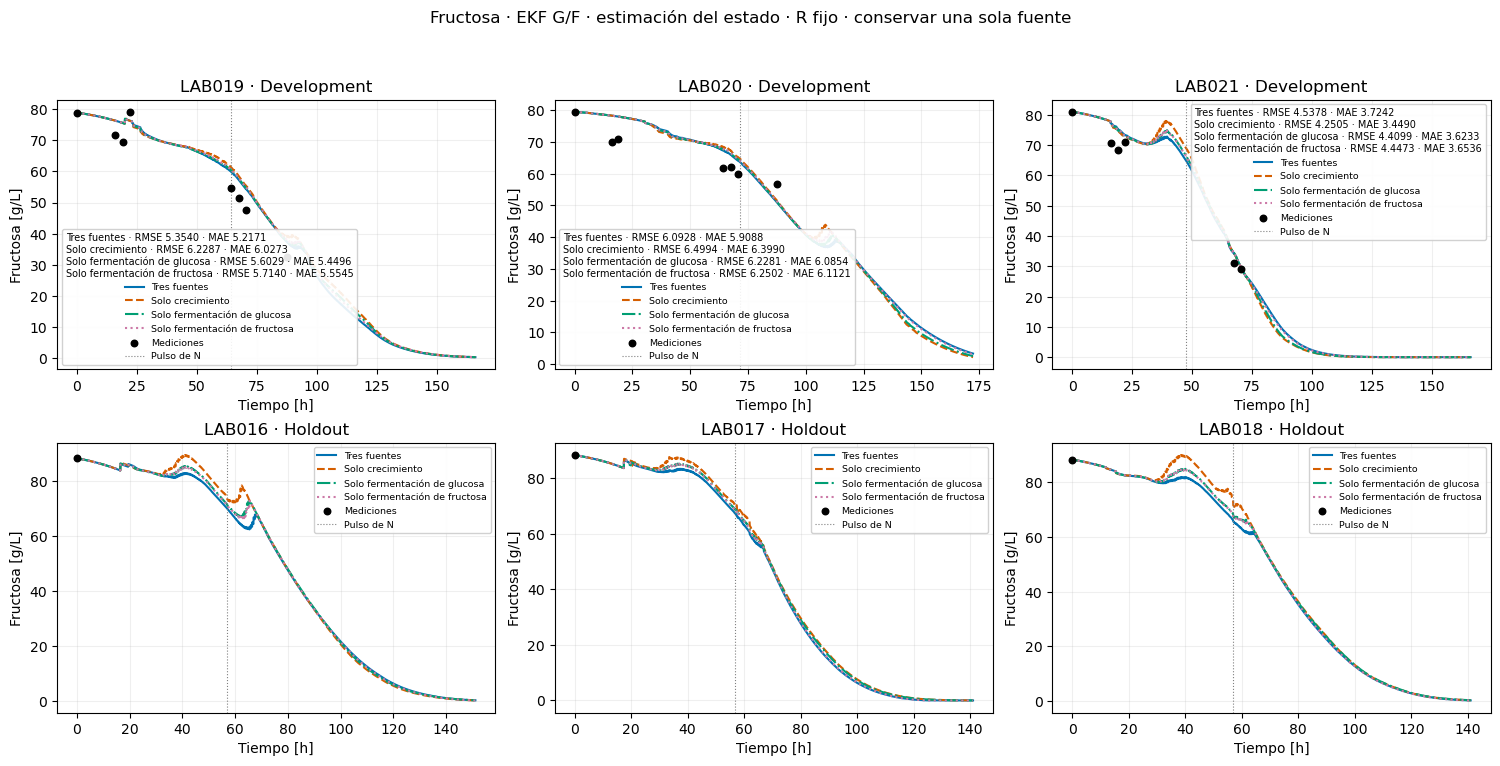

In [31]:
compare('F', 'Fructosa', cases=(WITHOUT_SOURCE, *SINGLE_CASES), comparison='conservar una sola fuente')

## Efecto observado al retirar fuentes

Con las amplitudes históricas, el aporte directo al estado acumulador de CO₂ emitido \(I\) proviene casi íntegramente de la fermentación de glucosa (45,63 %) y de fructosa (54,37 %). El crecimiento aporta el 100 % de la varianza de proceso que se inyecta directamente en biomasa y nitrógeno. Esos porcentajes se calculan por estado y sobre la trayectoria de referencia.

Al retirar una sola fuente, quitar la fermentación de fructosa produjo el mayor cambio en el error de CO₂ entre las tres parejas. En validación, el RMSE medio de CO₂ bajó 7,22 % y el MAE bajó 8,92 %. En desarrollo, el RMSE medio de etanol subió 11,46 %. Quitar la fermentación de glucosa redujo el RMSE medio de CO₂ en validación 4,41 %. Quitar el crecimiento lo cambió solo 0,19 %.

Con una sola fuente, el caso que conserva el ruido de crecimiento dio el menor RMSE y MAE medios de CO₂ en validación. Respecto de tres fuentes, bajaron 12,43 % y 15,11 %, respectivamente. El caso \(Q=0\), que aún propaga \(P_0\) y corrige con las observaciones, obtuvo reducciones similares de 12,10 % y 14,87 %. En desarrollo, el RMSE medio de fructosa aumentó 6,22 % con solo crecimiento. El conjunto de validación aporta mediciones de CO₂ y biomasa. La evaluación química de etanol y azúcares corresponde a desarrollo. Estos contrastes describen el efecto de retirar las fuentes con las amplitudes históricas fijas.

## Sensibilidad a la magnitud de \(D\)

Partimos de las tres fuentes activas con las intensidades históricas del EKF 05. En cada barrido, multiplicamos las entradas diagonales elegidas de \(D\) por un factor \(\alpha\). Probamos el crecimiento, cada fermentación por separado, las dos fermentaciones juntas y las tres fuentes juntas. Cada barrido utiliza 24 valores de \(\alpha\) entre 0 y 10, con más resolución cerca de cero y entre 1 y 2,5. Los demás términos de \(D\) conservan su valor de referencia. \(R=0{,}00218\) en cada ejecución.

El factor se aplica a **la varianza** de cada fuente. Como el código recibe amplitudes, estas se multiplican por \(\sqrt{\alpha}\). Por ejemplo, al multiplicar \(D_{22}\) por 0,25, la amplitud de la fuente de glucosa pasa de 0,08 a 0,04. Los lotes de validación se usan para describir el desempeño de los casos probados.

In [32]:
FACTORS = (0.0, 0.001, 0.003, 0.01, 0.03, 0.05, 0.1, 0.2, 0.25, 0.35, 0.5, 0.75,
           1.0, 1.25, 1.5, 1.75, 1.9, 2.0, 2.1, 2.25, 2.5, 4.0, 6.0, 10.0)
FAMILIES = {
    'Tres fuentes juntas': (0, 1, 2),
    'Dos fermentaciones juntas': (1, 2),
    'Crecimiento': (0,),
    'Fermentación de glucosa': (1,),
    'Fermentación de fructosa': (2,),
}
global_family = next(iter(FAMILIES))
global_plot_factors = (0.0, 0.1, 0.5, 2.0, 10.0)
global_plot_labels = {factor: f'D × {factor:g}' for factor in global_plot_factors}

# Reuse the equivalent cases already evaluated in the source removal experiment.
evaluated = {
    tuple(amplitudes): (RESULTS[case], METRICS.loc[METRICS.caso.eq(case)])
    for case, amplitudes in amplitudes_by_case.items()
}
sweep_metrics, sweep_diagonals, trajectory_metrics = [], [], []
for family, indices in FAMILIES.items():
    for factor in FACTORS:
        amplitudes = three_sources.copy()
        amplitudes[list(indices)] *= np.sqrt(factor)
        key = tuple(amplitudes)
        if key in evaluated:
            case_results, case_metrics = evaluated[key]
        else:
            case_results, case_metrics = {}, []
            for lab in LABS:
                result = core.run(DATA[lab], sigma=amplitudes, Rsd=np.sqrt(R))
                case_results[lab] = result
                metrics, info, _ = core.diagnostics(DATA, CHEM, lab, result)
                np.testing.assert_array_equal(result[2][:, 5] == 1, DATA[lab]['update'])
                assert info['min_eigenvalue'] > -1e-7
                case_metrics.append(metrics.assign(grupo=ROLE[lab]))
            case_metrics = pd.concat(case_metrics, ignore_index=True)
        sweep_metrics.append(case_metrics.drop(columns='caso', errors='ignore').assign(familia=family, factor=factor))
        sweep_diagonals.append({'familia': family, 'factor': factor, **dict(zip(SOURCE_LABELS, amplitudes[:3]**2))})
        if family == global_family and factor in global_plot_labels:
            label = global_plot_labels[factor]
            RESULTS[label] = case_results
            trajectory_metrics.append(case_metrics.assign(caso=label))

SWEEP = pd.concat(sweep_metrics, ignore_index=True)
D_SWEEP = pd.DataFrame(sweep_diagonals).set_index(['familia', 'factor'])
METRICS = pd.concat([METRICS, *trajectory_metrics], ignore_index=True)
assert len(D_SWEEP) == len(FAMILIES) * len(FACTORS)
sweep_counts = SWEEP.pivot(index=keys, columns=['familia', 'factor'], values='n')
assert sweep_counts.eq(sweep_counts[(global_family, 1.0)], axis=0).all().all()

group_keys = ['grupo', 'variable', 'unit']
MEANS = SWEEP.groupby([*group_keys, 'familia', 'factor'])[['RMSE', 'MAE']].mean()
reference = MEANS.xs((global_family, 1.0), level=('familia', 'factor'))
CHANGE = 100 * (MEANS.div(reference, axis=0, level=None) - 1)
display(D_SWEEP.style.format('{:.3e}').set_caption('Entradas diagonales de D probadas'))
for metric in ('RMSE', 'MAE'):
    values = MEANS[metric].unstack('factor').reindex(columns=FACTORS)
    display(values.style.format('{:.5f}').set_caption(f'{metric} medio por grupo, variable y factor'))


yan_factors = [0.0, 0.5, 1.0, 1.5, 1.75, 1.9, 2.0, 2.1, 2.25, 2.5, 4.0, 10.0]
yan = SWEEP.loc[
    SWEEP.variable.eq('N') & SWEEP.familia.isin([global_family, 'Dos fermentaciones juntas'])
    & SWEEP.factor.isin(yan_factors)
]
for metric in ('RMSE', 'MAE'):
    table = yan.pivot(index=['familia', 'LAB'], columns='factor', values=metric)
    display(table.style.format('{:.2f}').set_caption(f'{metric} de YAN por lote [mg/L]'))


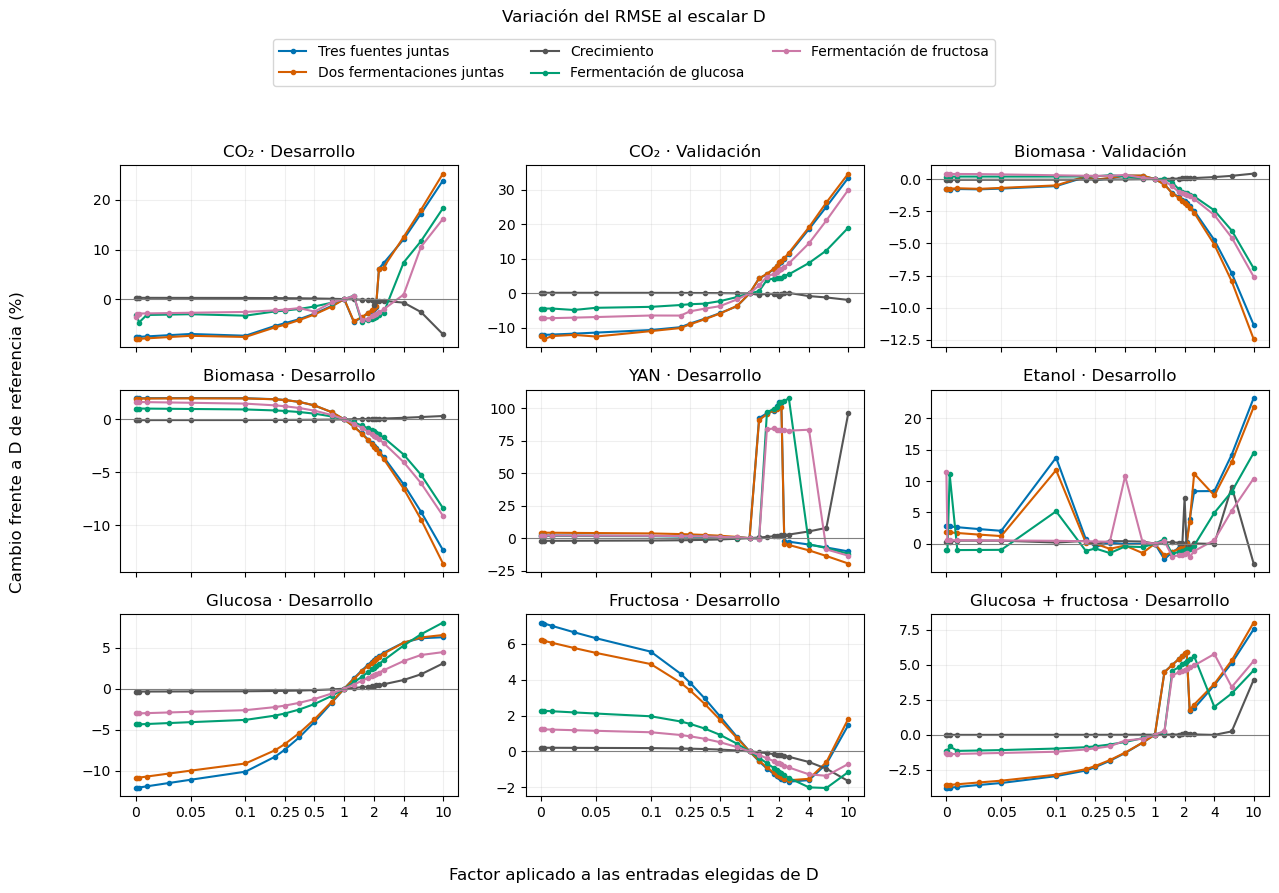

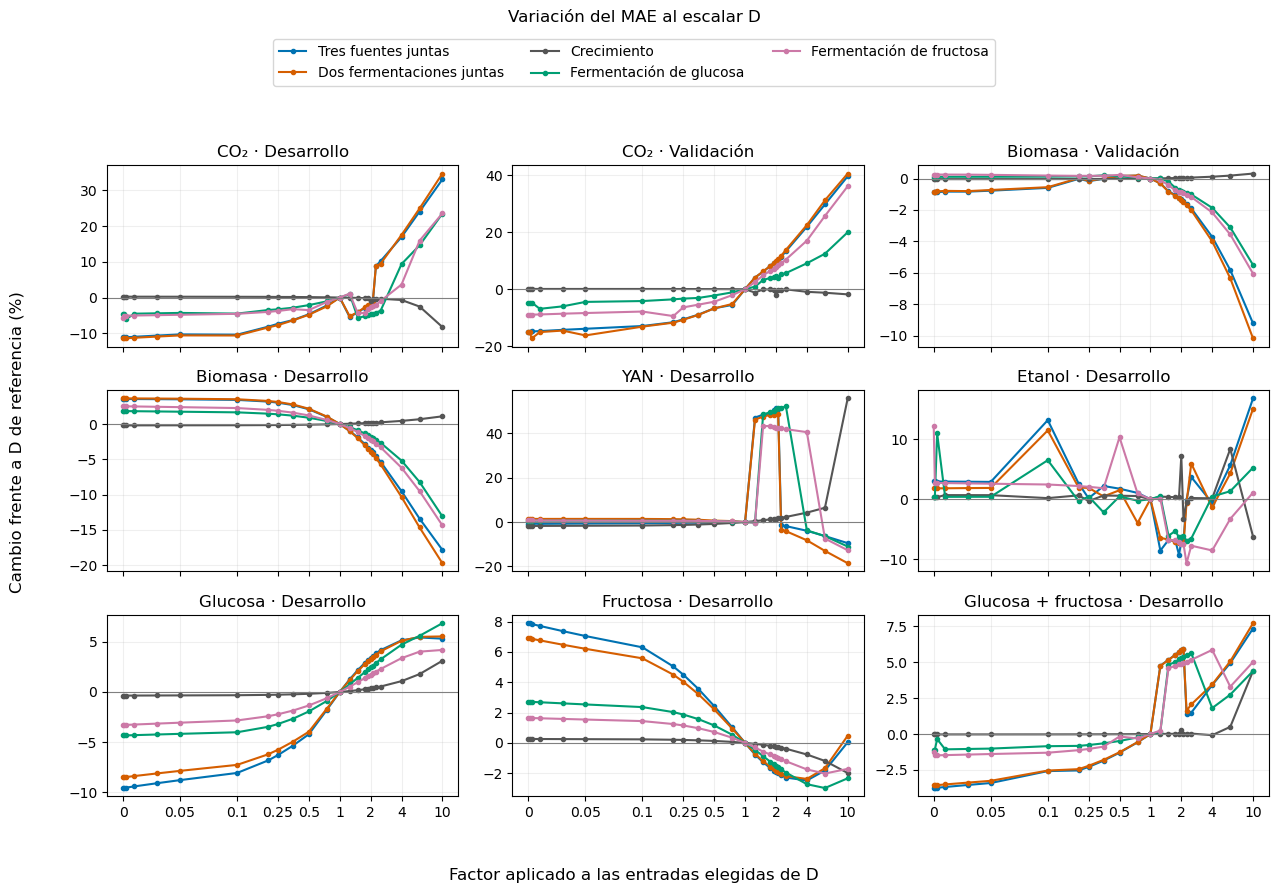

In [33]:
family_colors = ('#0072B2', '#D55E00', '#555555', '#009E73', '#CC79A7')
panels = [
    ('Development', 'CO2', 'CO₂ · Desarrollo'),
    ('Holdout', 'CO2', 'CO₂ · Validación'),
    ('Holdout', 'X', 'Biomasa · Validación'),
    ('Development', 'X', 'Biomasa · Desarrollo'),
    ('Development', 'N', 'YAN · Desarrollo'),
    ('Development', 'E', 'Etanol · Desarrollo'),
    ('Development', 'G', 'Glucosa · Desarrollo'),
    ('Development', 'F', 'Fructosa · Desarrollo'),
    ('Development', 'GF', 'Glucosa + fructosa · Desarrollo'),
]
for metric in ('RMSE', 'MAE'):
    fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
    for ax, (group, variable, title) in zip(axes.flat, panels):
        panel = CHANGE.xs((group, variable), level=('grupo', 'variable'))
        for color, family in zip(family_colors, FAMILIES):
            values = panel.xs(family, level='familia')[metric].droplevel('unit').reindex(FACTORS)
            ax.plot(FACTORS, values, marker='o', ms=3, color=color, label=family)
        ax.axhline(0, color='0.5', linewidth=0.8)
        ax.set_title(title)
        ax.set_xscale('symlog', linthresh=0.1)
        ticks = [0, 0.05, 0.1, 0.25, 0.5, 1, 2, 4, 10]
        ax.set_xticks(ticks, [f'{factor:g}' for factor in ticks])
        ax.grid(alpha=0.2)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 0.955))
    fig.suptitle(f'Variación del {metric} al escalar D')
    fig.supxlabel('Factor aplicado a las entradas elegidas de D')
    fig.supylabel('Cambio frente a D de referencia (%)')
    fig.tight_layout(rect=(0.03, 0.03, 1, 0.88))
    plt.show()


## Trayectorias con escalado conjunto de las tres fuentes

Se superponen el caso de referencia y los factores 0, 0,1, 0,5, 2 y 10. El factor 0 anula las tres intensidades y da \(Q=0\). Los factores 2 y 10 muestran la respuesta al ampliar el ruido de proceso.

In [34]:
sweep_colors = ('#D55E00', '#009E73', '#CC79A7', '#785EF0', '#A66A00')
sweep_styles = ('--', '-.', ':', (0, (5, 2)), (0, (3, 1, 1, 1)))
for color, linestyle, label in zip(sweep_colors, sweep_styles, global_plot_labels.values()):
    COLORS[label], STYLES[label] = color, linestyle
sweep_trajectory_cases = (WITHOUT_SOURCE, *global_plot_labels.values())


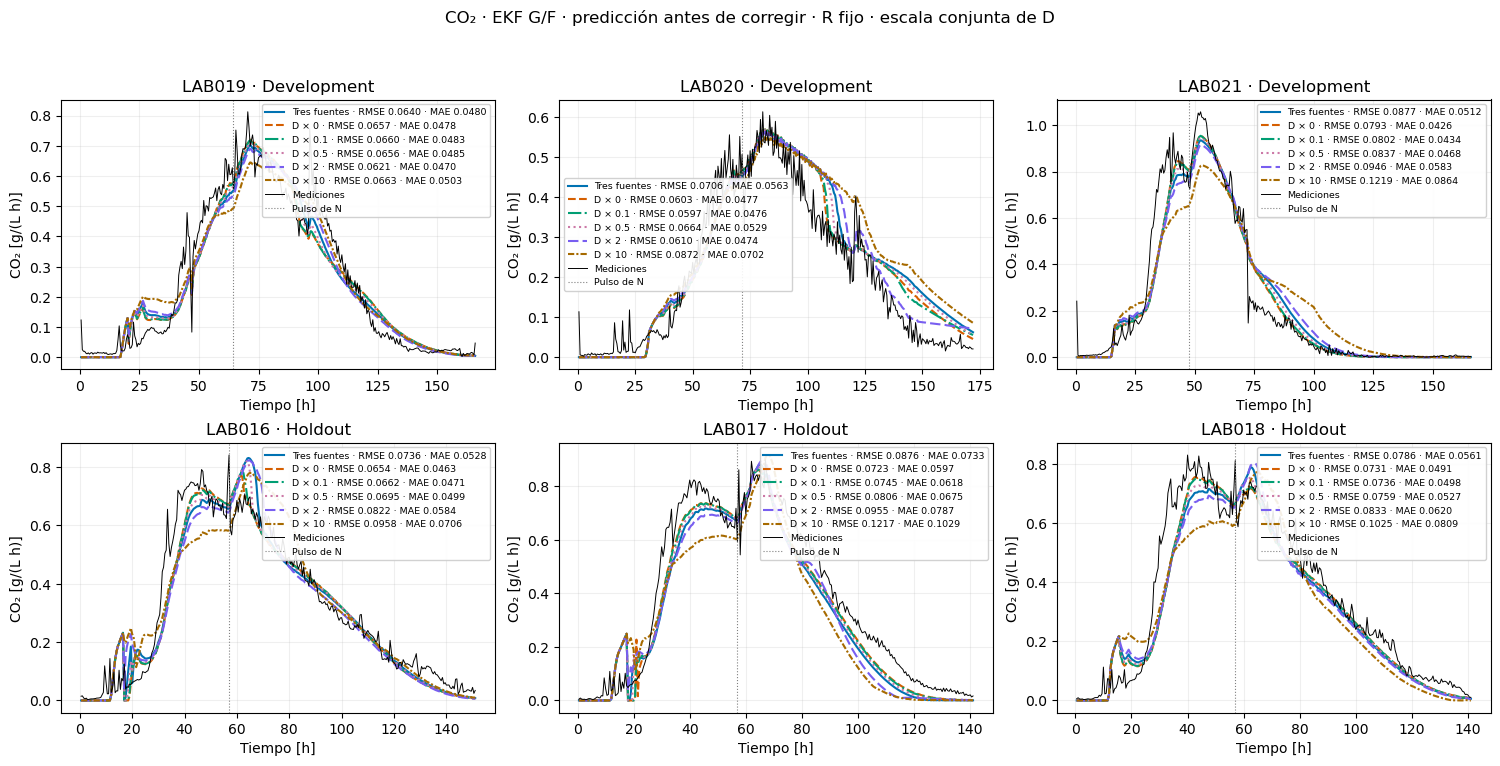

In [35]:
compare('CO2', 'CO₂', cases=sweep_trajectory_cases, comparison='escala conjunta de D')

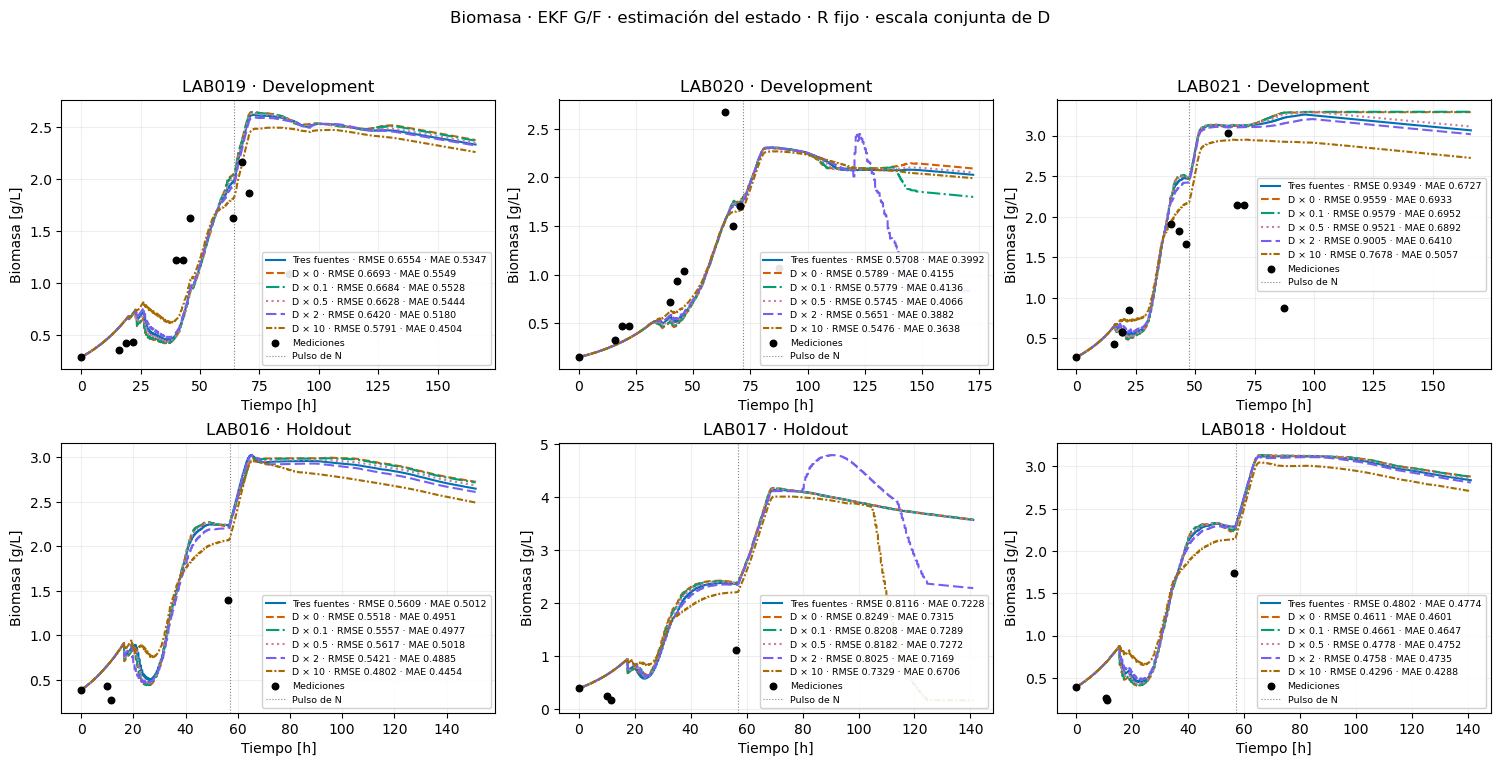

In [36]:
compare('X', 'Biomasa', cases=sweep_trajectory_cases, comparison='escala conjunta de D')

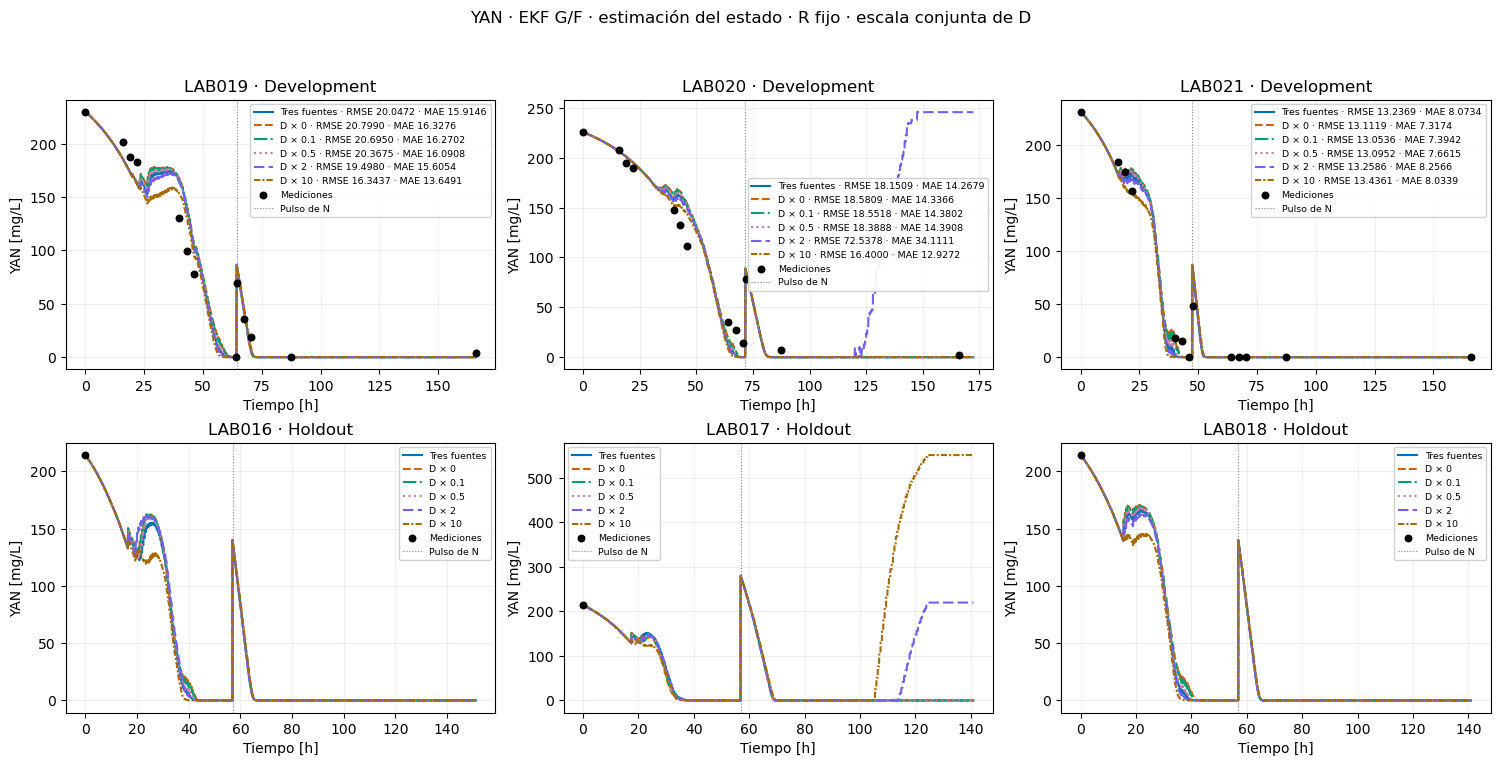

In [37]:
compare('N', 'YAN', cases=sweep_trajectory_cases, comparison='escala conjunta de D')

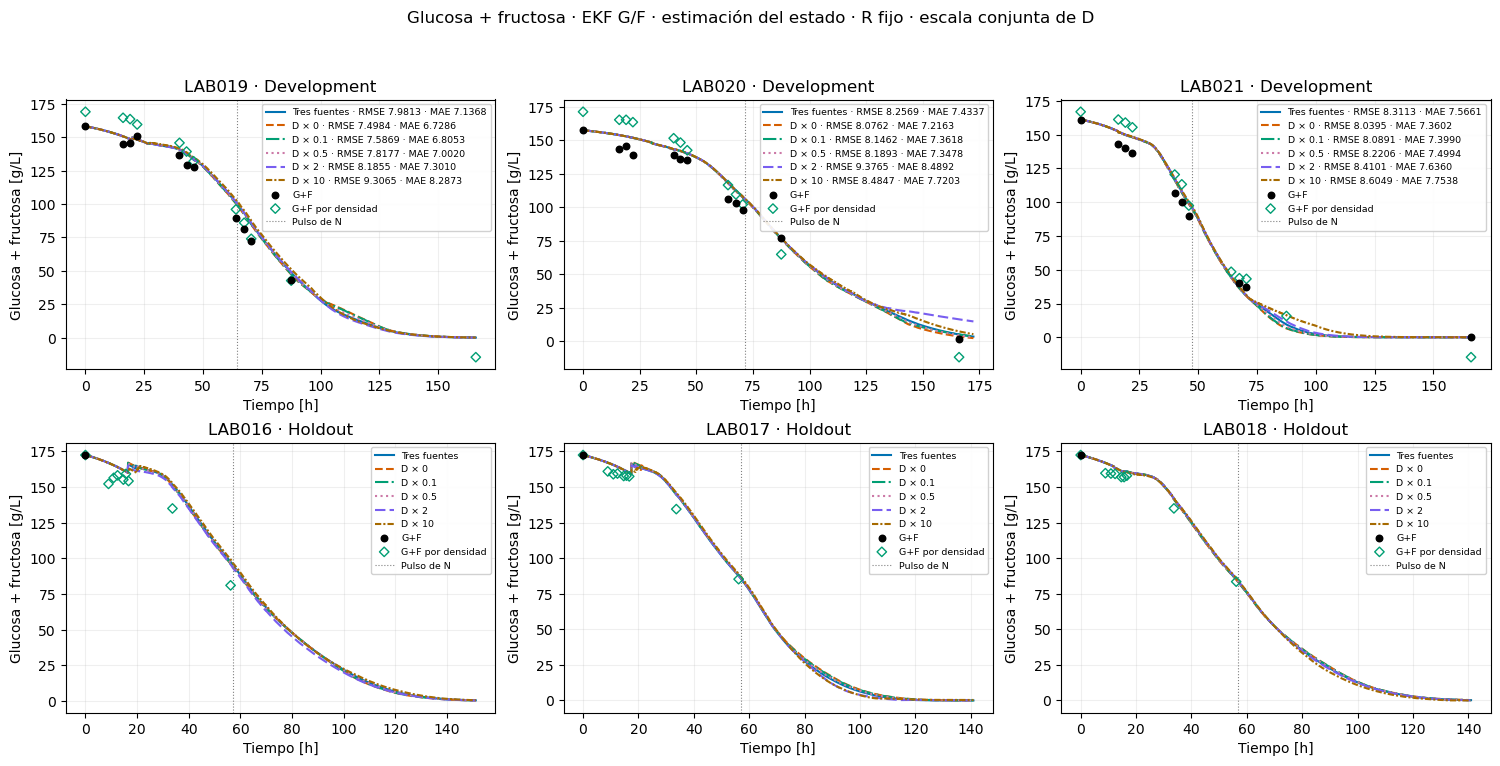

In [38]:
compare('GF', 'Glucosa + fructosa', cases=sweep_trajectory_cases, comparison='escala conjunta de D')

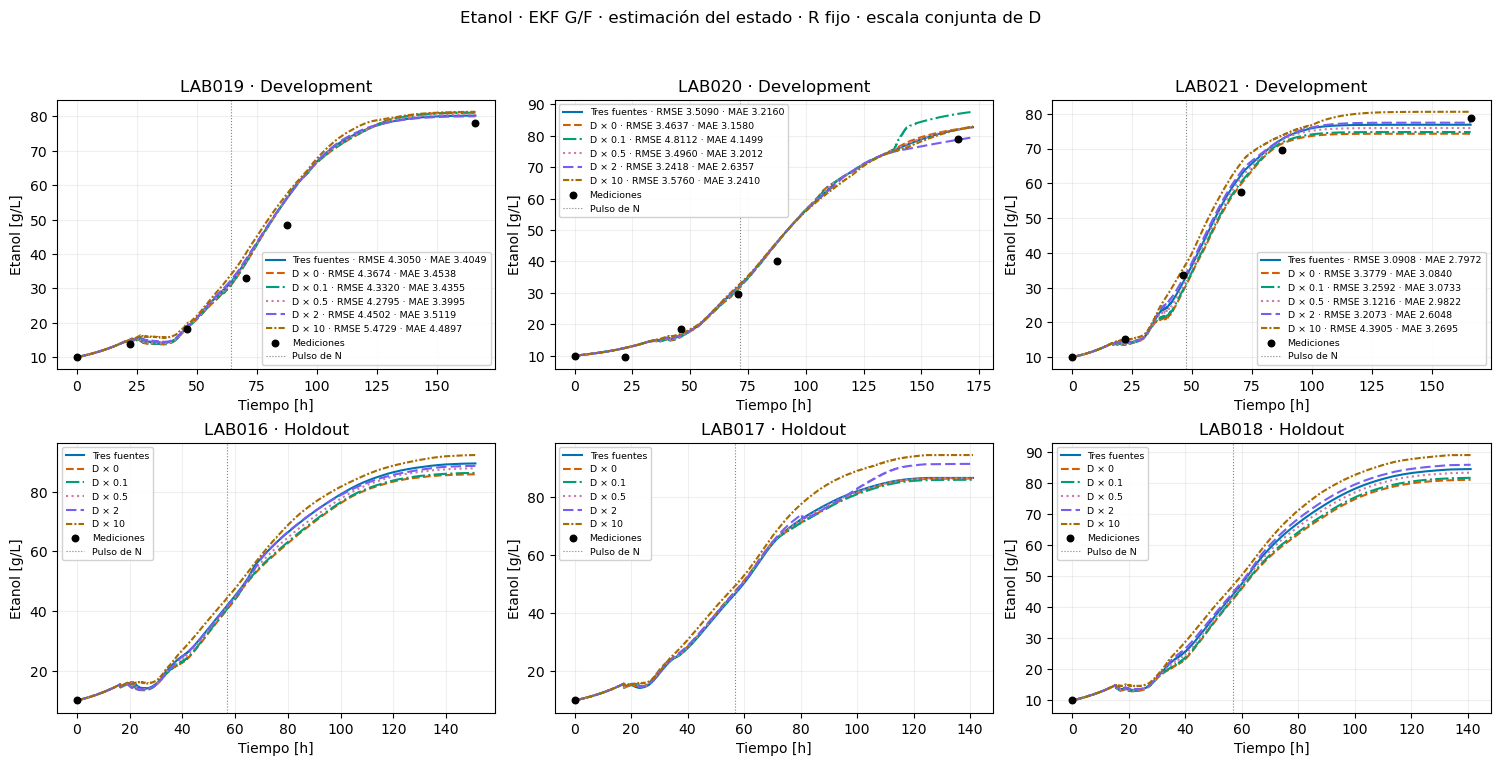

In [39]:
compare('E', 'Etanol', cases=sweep_trajectory_cases, comparison='escala conjunta de D')

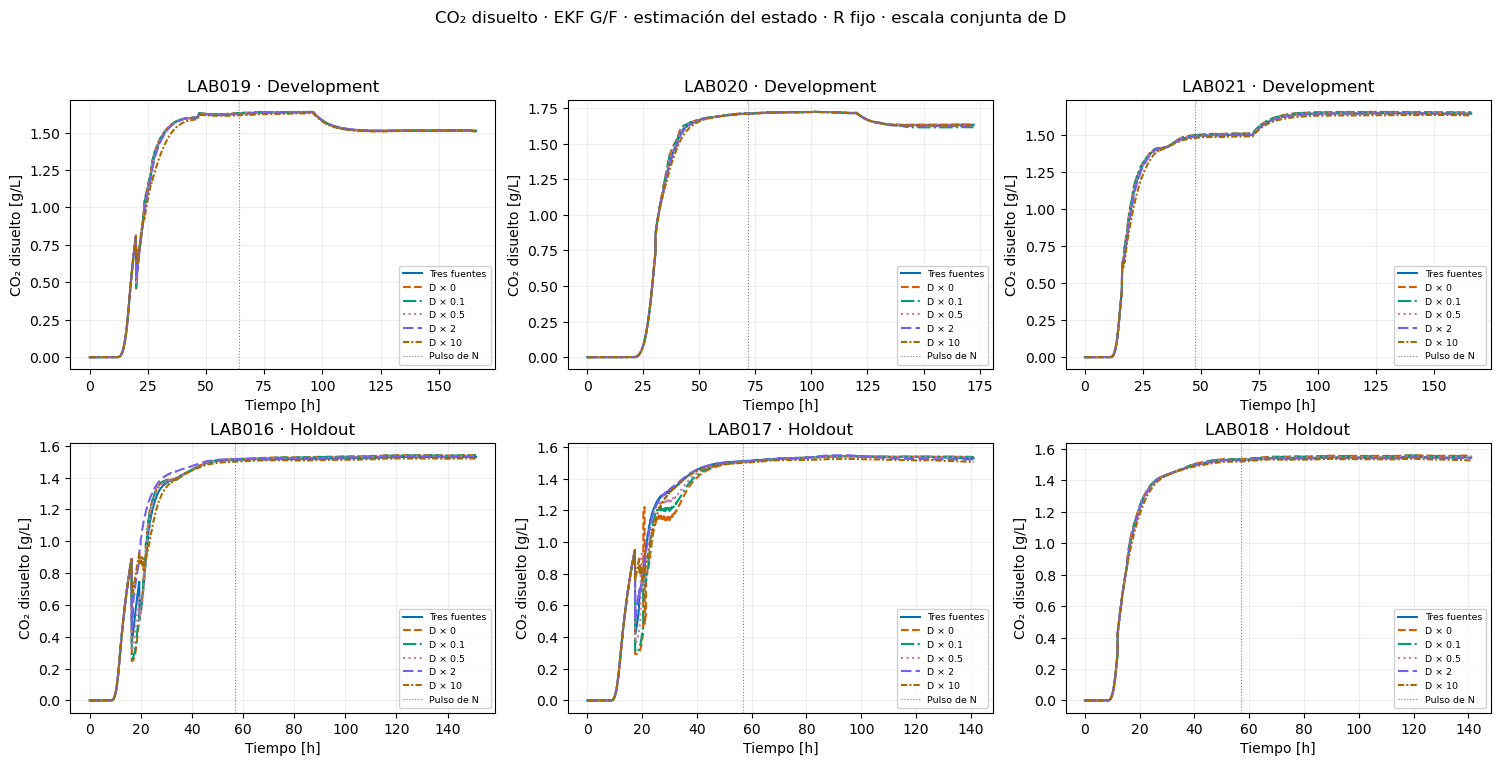

In [40]:
compare('Cd', 'CO₂ disuelto', cases=sweep_trajectory_cases, comparison='escala conjunta de D')

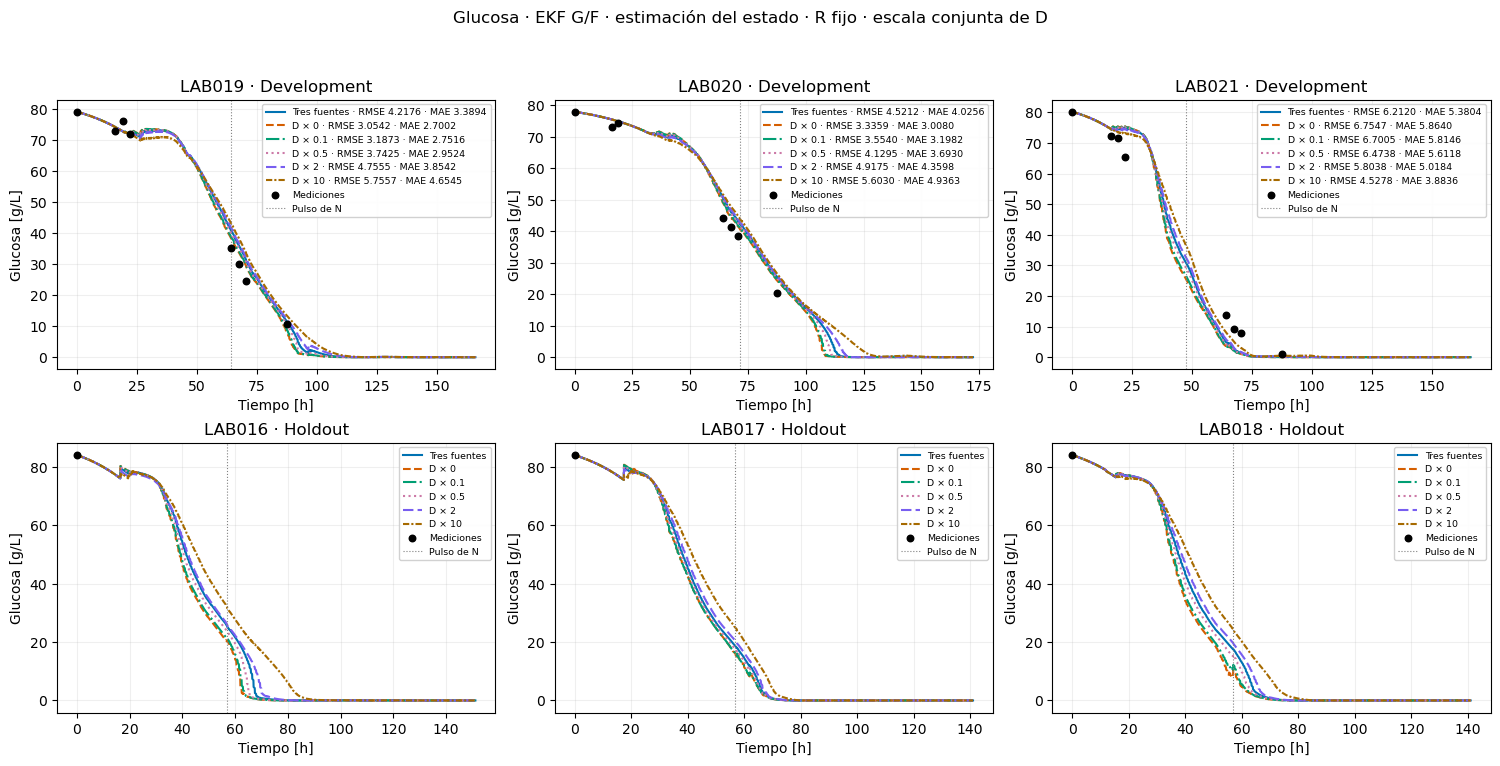

In [41]:
compare('G', 'Glucosa', cases=sweep_trajectory_cases, comparison='escala conjunta de D')

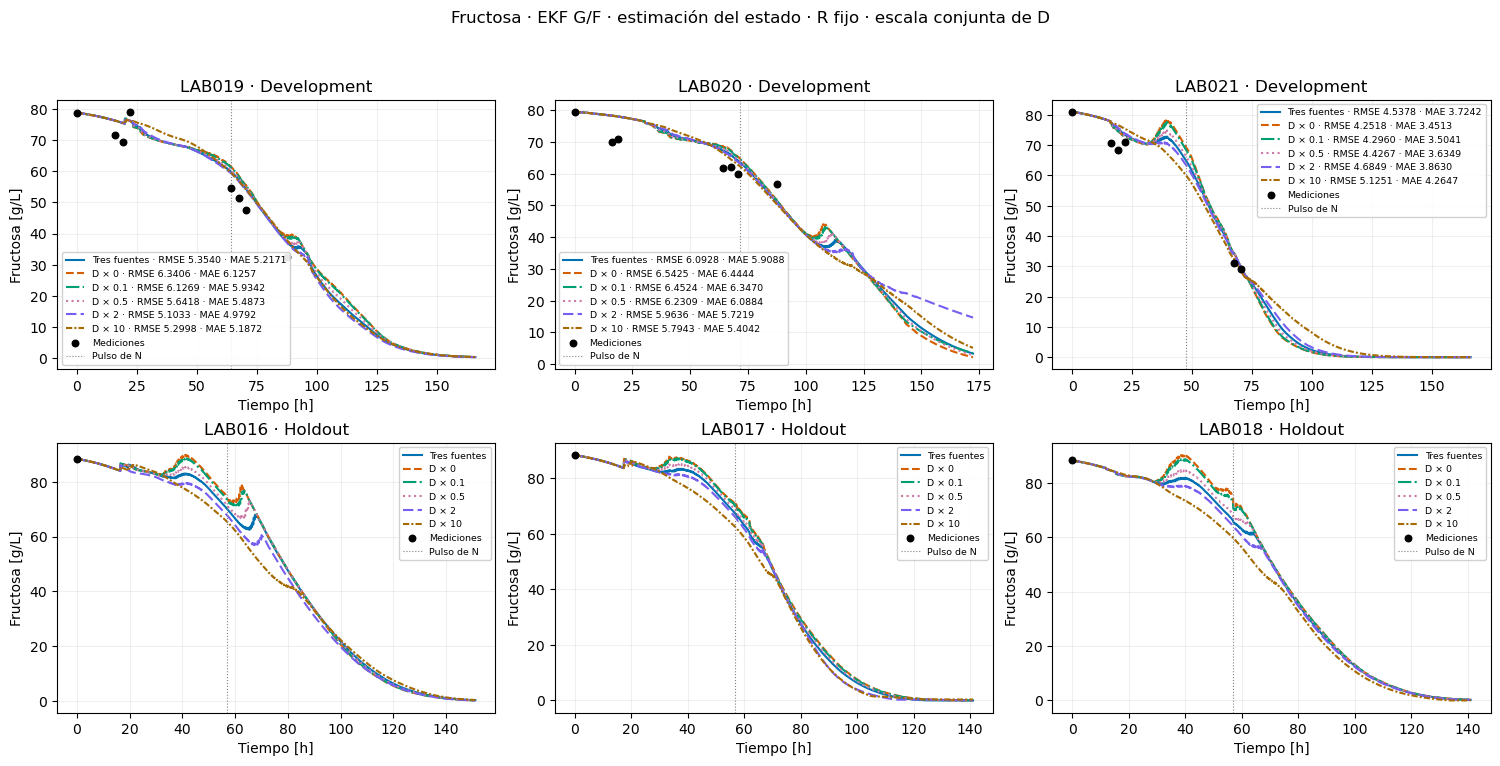

In [42]:
compare('F', 'Fructosa', cases=sweep_trajectory_cases, comparison='escala conjunta de D')

## Resultado del barrido ampliado

La referencia \(D\times0\) de las figuras es el EKF con \(Q=0\). El filtro sigue propagando \(P_0\) y corrigiendo con las mediciones de CO₂.

Al escalar las tres fuentes juntas, el RMSE medio de CO₂ en validación fue 0,07026 g/(L·h) con \(D\times0\), 0,07992 con \(D\times1\) y 0,10666 con \(D\times10\). En los mismos lotes, el RMSE de biomasa bajó de 0,61755 g/L a 0,54757 g/L entre los factores 1 y 10. El aumento de \(D\) tiene efectos distintos según el estado evaluado.

En YAN, el promedio de desarrollo oculta un efecto concentrado en LAB020. Al escalar las tres fuentes juntas, su RMSE de YAN pasa de 18,15 mg/L con el factor 1 a 72,54 mg/L con el factor 2 y vuelve a 17,63 mg/L con el factor 2,25. En la trayectoria con \(D\times2\) se observa un rebote tardío del YAN estimado después del pulso. Como el balance de nitrógeno solo permite consumo entre pulsos, el aumento proviene de las correcciones del EKF. En LAB017 también se observan rebotes tardíos en la estimación. La validación carece de mediciones de YAN para evaluar esas trayectorias.

## Origen del rebote de YAN en LAB020

Se reconstruye cada corrección de YAN al escalar juntas las tres fuentes por 2 y 2,25, con \(R=0{,}00218\). En cada ventana asimilada, la corrección sin recorte es \(K_N\nu\), donde \(\nu\) es el CO₂ medido menos el predicho y \(K_N=\operatorname{Cov}^{-}(N,\widehat y_{\mathrm{CO_2}})/S\). La corrección efectiva incluye la proyección del YAN a cero cuando \(N^-+K_N\nu<0\).

La reconstrucción usa el estado y la covarianza guardados en el paso anterior. Se comprueba contra las innovaciones, sus varianzas y los estados corregidos que devuelve el EKF. El pulso de nitrógeno se incorpora al valor predicho, antes de calcular la corrección por CO₂.

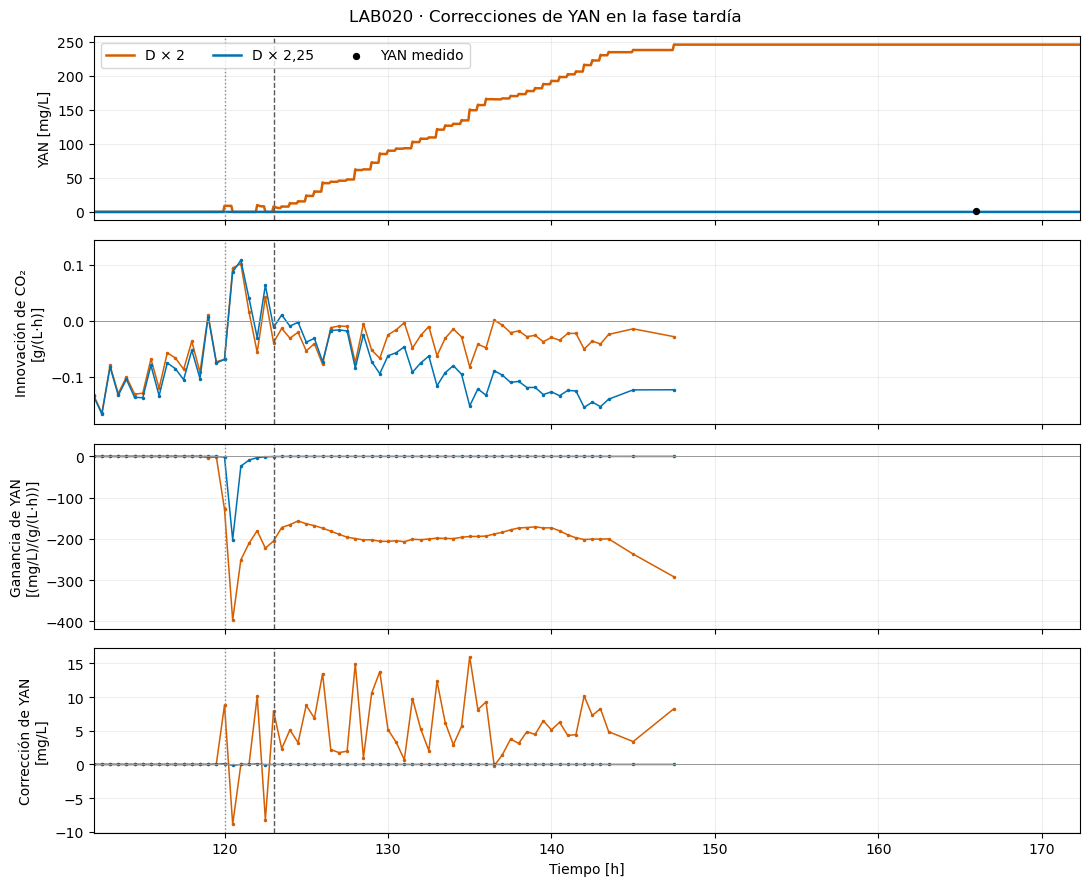

In [43]:
lab = 'LAB020'
data = DATA[lab]
grid = data['grid']
assimilation = np.flatnonzero(data['update'])
last_pulse = grid[data['doses'] > 0][-1]
scale_outer = np.outer(core.SCALE, core.SCALE)
kla, gain = core.ARCHIVED_GAS
trace_rows, yan_trajectories = [], {}

for multiplier in (2.0, 2.25):
    amplitudes = three_sources * np.sqrt(multiplier)
    frames, covariances, diagnostics = core.run(data, sigma=amplitudes, Rsd=np.sqrt(R))
    yan_trajectories[multiplier] = frames[:, 1] * 1000
    D = np.diag(amplitudes**2)
    for i in assimilation:
        previous_state = frames[i - 1]
        start, end = grid[i - 1], grid[i]
        prior, jacobian = core.jacobian(
            previous_state / core.SCALE, start, end, data['available'],
            data['temperature'], data['S0'], kla, gain, 1/60,
        )
        prior[1] += data['doses'][i] / core.SCALE[1]
        temperature = core.temperature_at(start, data['available'], data['temperature'])
        L = core.noise_L(previous_state, temperature, data['S0'], kla, gain)
        previous_covariance = covariances[i - 1] / scale_outer
        propagated = jacobian @ previous_covariance @ jacobian.T
        from_previous_yan = jacobian[1, 1] * (previous_covariance @ jacobian[6])[1]
        injected = (end - start) * (L @ D @ L.T) / scale_outer
        prior_covariance = propagated + injected
        prior_covariance = (prior_covariance + prior_covariance.T) / 2

        predicted_co2 = prior[6] / 0.5
        innovation = data['y'][i] - predicted_co2
        variance = 4 * prior_covariance[6, 6] + R
        np.testing.assert_allclose([predicted_co2, innovation, variance], diagnostics[i, :3],
                                   rtol=1e-8, atol=1e-10)
        kalman_gain = 2 * prior_covariance[:, 6] / variance
        updated = prior + kalman_gain * innovation
        yan_conversion = core.SCALE[1] * 1000
        yan_before = prior[1] * yan_conversion
        yan_after = frames[i, 1] * 1000
        np.testing.assert_allclose(np.maximum(updated[:6], 0) * core.SCALE[:6],
                                   frames[i, :6], rtol=1e-8, atol=1e-10)

        trace_rows.append({
            'factor': multiplier, 'hora': end, 'CO₂ medido': data['y'][i],
            'CO₂ predicho': predicted_co2, 'Innovación': innovation, 'S': variance,
            'Covarianza YAN–CO₂': 2 * prior_covariance[1, 6] * yan_conversion,
            'Covarianza propagada': 2 * propagated[1, 6] * yan_conversion,
            'Covarianza vía YAN previo': 2 * from_previous_yan * yan_conversion,
            'Sensibilidad al YAN previo': jacobian[1, 1],
            'Glucosa posterior': frames[i, 2], 'Fructosa posterior': frames[i, 3],
            'Covarianza inyectada': 2 * injected[1, 6] * yan_conversion,
            'Ganancia YAN': kalman_gain[1] * yan_conversion,
            'Corrección sin recorte': kalman_gain[1] * innovation * yan_conversion,
            'Corrección efectiva': yan_after - yan_before,
            'YAN previo': yan_before, 'YAN posterior': yan_after,
            'Estados recortados': ', '.join(state for state, value in zip(core.STATES[:6], updated[:6])
                                            if value < 0) or '—',
        })

yan_trace = pd.DataFrame(trace_rows).set_index(['factor', 'hora']).sort_index()
left = yan_trace.loc[2.0]
right = yan_trace.loc[2.25]
assert left.index.equals(right.index)
late = left.index > last_pulse
gap = (left['YAN posterior'] - right['YAN posterior']).loc[late]
first_rebound = gap[gap >= 5.0].index[0]
largest_rise = left.loc[late, 'Corrección efectiva'].idxmax()
largest_difference = (left['Corrección efectiva'] - right['Corrección efectiva']).loc[late].idxmax()
below_threshold = gap.loc[gap < 5.0]
last_below = below_threshold.index[-1]
sustained_rebound = gap.index[gap.index > last_below][0]
hours_to_show = sorted({first_rebound, first_rebound + 0.5, last_below,
                        sustained_rebound, sustained_rebound + 0.5, largest_rise,
                        largest_difference} & set(left.index))
selected = yan_trace.reset_index().loc[lambda rows: rows.hora.isin(hours_to_show)]
selected = selected.set_index(['hora', 'factor']).sort_index()

display(selected[['CO₂ medido', 'CO₂ predicho', 'Innovación', 'S', 'Covarianza YAN–CO₂',
                  'Covarianza propagada', 'Covarianza inyectada', 'Ganancia YAN',
                  'YAN previo', 'Corrección sin recorte', 'Corrección efectiva', 'YAN posterior',
                  'Estados recortados']].style.format(precision=5).set_caption(
                      'Primera brecha de 5 mg/L, inicio del rebote sostenido y correcciones máximas'))
display(selected[['Glucosa posterior', 'Fructosa posterior', 'Sensibilidad al YAN previo',
                  'Covarianza vía YAN previo', 'Covarianza propagada']].style.format(precision=5)
        .set_caption('Estados y propagación de la covarianza en las mismas ventanas'))

# A common time axis shows whether a change in innovation or gain precedes the rebound.
start_plot = max(last_pulse, first_rebound - 8)
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for multiplier, color in [(2.0, '#D55E00'), (2.25, '#0072B2')]:
    trace = yan_trace.loc[multiplier]
    label = f'D × {multiplier:g}'.replace('.', ',')
    axes[0].plot(grid, yan_trajectories[multiplier], color=color, lw=1.8, label=label)
    for ax, column in zip(axes[1:], ('Innovación', 'Ganancia YAN', 'Corrección efectiva')):
        ax.plot(trace.index, trace[column], color=color, marker='.', ms=3, lw=1.1, label=label)
sample = CHEM.loc[CHEM.lab.eq(lab)].dropna(subset=[core.CHEM_COLS['N']])
axes[0].scatter(sample.t_h, 1000 * sample[core.CHEM_COLS['N']], color='black', s=18,
                zorder=4, label='YAN medido')
for ax in axes:
    ax.axvline(first_rebound, color='0.55', linestyle=':', lw=1)
    ax.axvline(sustained_rebound, color='0.35', linestyle='--', lw=1)
    ax.grid(alpha=0.2)
for ax in axes[1:]:
    ax.axhline(0, color='0.6', lw=0.7)
axes[0].legend(loc='upper left', ncol=3)
axes[0].set_ylabel('YAN [mg/L]')
axes[1].set_ylabel('Innovación de CO₂\n[g/(L·h)]')
axes[2].set_ylabel('Ganancia de YAN\n[(mg/L)/(g/(L·h))]')
axes[3].set_ylabel('Corrección de YAN\n[mg/L]')
axes[3].set_xlabel('Tiempo [h]')
axes[3].set_xlim(start_plot, grid[-1])
fig.suptitle('LAB020 · Correcciones de YAN en la fase tardía')
fig.tight_layout()
plt.show()


### Corrección que inicia el rebote sostenido

A las 120 h los dos filtros tienen casi la misma innovación de CO₂ (−0,06885 y −0,06883 g/(L·h)). El factor 2 añade 8,81 mg/L de YAN y el factor 2,25 añade 0,12 mg/L. La medición de las 120,5 h produce una innovación positiva y ambos casos proyectan el YAN a cero. Esa primera subida dura una sola ventana.

El rebote sostenido comienza a las **123 h**. Ambos casos parten de YAN predicho igual a cero. Con factor 2, el CO₂ medido está por debajo del predicho, \(\nu=-0{,}03875\) g/(L·h), y la ganancia de YAN es \(K_N=-205{,}02\ (\mathrm{mg/L})/(\mathrm{g/(L\cdot h)})\). El producto de los dos valores negativos agrega **7,94 mg/L**. Con factor 2,25 la innovación también es negativa, pero \(K_N=-0{,}284\) y la corrección es **0,0033 mg/L**. A las 135 h, una sola actualización agrega **15,97 mg/L** con factor 2 y **0,0017 mg/L** con factor 2,25.

La diferencia de ganancia a las 123 h viene sobre todo de la covarianza propagada entre YAN y CO₂. Sus valores son −1,61251 con factor 2 y −0,00209 con factor 2,25, en \((\mathrm{mg/L})(\mathrm{g/(L\cdot h)})\). La inyección directa del último paso es del orden de \(10^{-5}\) en ambos casos. Tras la corrección de las 122,5 h, el YAN queda en cero en ambos casos, pero la glucosa queda recortada a cero con factor 2 y en 0,03757 g/L con factor 2,25. En esa zona, la cinética desactiva el crecimiento al agotarse un azúcar. En el paso que termina a las 123 h, la sensibilidad del YAN predicho a su valor anterior es 1,000 con factor 2 y 0,837 con factor 2,25. Las trayectorias ya venían propagando covarianzas distintas. El recorte a cero actúa sobre la estimación del estado y conserva la covarianza que calculó el EKF.

Con factor 2, las correcciones positivas posteriores sostienen el rebote hasta unos 247 mg/L. El pulso de nitrógeno ocurrió a las 71,67 h. El aumento tardío corresponde a la estimación del EKF a partir del CO₂ y el YAN medido al final permanece cerca de cero.